<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/06_Android_Malware_Detection/VQC_PhishingMalwareSpam_RosaRemedios2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VQC parameterisations for phishing, Android malware and spam: Rosa-Remedios and Caballero-Gil (2024) step by step

This notebook re-implements, runs and checks the experiments of

> Carlos Rosa-Remedios and Pino Caballero-Gil, "Optimizing quantum machine learning for proactive cybersecurity",
> *Optimization and Engineering* 26, 2321-2353 (2025; published online 14 December 2024).
> https://doi.org/10.1007/s11081-024-09934-z

The paper publishes no code. Everything below is written from its Sections 4-6 with the software stack it names (Python, scikit-learn,
Qiskit, qiskit-machine-learning's `VQC`).

**What the notebook does.** It downloads the three UCI datasets of the paper (Website Phishing, NATICUSdroid Android permissions, Spambase)
plus the second phishing dataset used for Table 15, rebuilds the paper's small balanced working sets (300 / 300 / 150 records), trains the
classical `SVC` baseline of Table 7, and then runs the paper's grid of **Variational Quantum Classifiers**: `ZFeatureMap` + one of three
ansaetze (`RealAmplitudes` without entanglement, `EfficientSU2`, `ExcitationPreserving`) + one of three optimisers (`COBYLA`, `POWELL`,
`SLSQP`), 100 iterations each, on 9 or 10 qubits. Train and test accuracies fill the paper's Tables 8, 9 and 10; the paper's
Tables 7, 11, 12, 13 and 15 and its qualitative conclusions are then checked claim by claim.

**A note on the simulator.** The paper's grid needed up to 12 hours per cell on a desktop CPU. Qiskit's `VQC` simulates one circuit at a
time (about 0.1 s each here). This notebook therefore simulates the *same* circuits for the whole training batch at once with a small
exact NumPy simulator and an adjoint gradient (Section 5), and **proves equivalence** with Qiskit before using it: statevectors agree to
1e-10 with `qiskit.quantum_info.Statevector`, and the class probabilities and the loss gradient agree with `VQC`'s own neural network and
its parameter-shift gradient. The optimisers are the unchanged `qiskit_machine_learning.optimizers` classes.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs pinned Qiskit
versions; if Colab asks to restart the session, restart and run all again. No GPU, no IBM Quantum account and no Hugging Face token are needed
(all four datasets are public UCI files).

**Runtime.** `FAST_MODE = True` (40 / 40 / 25 records per class, SLSQP limited to 25 iterations, POWELL to 100 evaluations) takes about 7 minutes on a busy 4-core laptop CPU. `FAST_MODE = False` uses the paper's
sample sizes (210 / 210 / 105 training records) and 100 iterations; the budgets that still had to be capped are stated in Section 6. The committed outputs are those of a full run
(`FAST_MODE = False`) that took about 2 hours on that CPU (training grid 112 min, seed study 6 min); `POWELL` (up to 800 evaluations per run) dominates.

**What you get at the end.** Re-computed Tables 7-13 and 15, the paper's Figs. 8-13 (SVC and VQC confusion matrices) redrawn from real
runs, loss curves, the circuits actually executed, and a verdict ("reproduced" / "not reached" / "exceeded" / "cannot be checked") for each
checkable claim, followed by a critical reading and five exercises.

## The paper in one page

**Problem.** Show that Quantum Machine Learning can be applied to three classical security-classification tasks and find "the most optimal
parameterisation" of a variational quantum classifier for each: website phishing (phishing vs legitimate), Android malware (malware vs benign
from requested permissions) and spam e-mail (spam vs ham from word and character frequencies).

**Decision.** Binary classification; the class is read from the measured bit-string (Qiskit `VQC` default interpretation).

**Method.** A four-phase recipe: choose datasets -> adapt them (numeric features, reduction, normalisation, balancing) -> run a classical
baseline -> run the quantum model for every combination of feature map, ansatz and optimiser on two processors (Intel and Apple M2 Pro).
Feature map `ZFeatureMap` (H then P(2x), repeated twice, Fig. 2); ansaetze `RealAmplitudes` (entanglement removed, Fig. 3), `EfficientSU2`
(Fig. 4) and `ExcitationPreserving` (Fig. 5); optimisers `COBYLA`, `POWELL`, `SLSQP`, 100 iterations each; one qubit per feature
(9, 9 and 10 qubits); simulation only.

**Data.** (1) Website Phishing (Abdelhamid 2016, UCI id 379): 1,353 sites, 9 integer features; 150 per class sampled. (2) NATICUSdroid
(Mathur 2021, UCI id 722): 29,932 apps (UCI file: 29,332), 86 permissions, reduced to 9 by correlation and ANOVA; 300 apps balanced. (3) Spambase
(Hopkins 1999, UCI id 94): 4,601 e-mails, 57 features reduced to 10 by ANOVA; 150 e-mails balanced. (4) For Table 15 a second phishing set
(Olowookere 2021; 11,055 sites, 31 attributes = UCI id 327) reduced to the 9 features of Table 14.

**Preprocessing.** `.arff` to CSV; stratified sampling; `MinMaxScaler`.

**Claims.** Table 7 (classical SVC, train / test accuracy): phishing 0.92 / 0.93, Android 0.99 / 0.98, spam 0.93 / 0.87. Tables 8-10 (VQC
train / test accuracy for 8 of the 9 ansatz x optimiser cells per dataset, the ninth, `ExcitationPreserving` + `SLSQP`, exceeded 12 h).
Conclusions: (i) the choice of ansatz matters less than the choice of optimiser, the best results come from `SLSQP` and `POWELL`; (ii)
`ExcitationPreserving` costs time and "considerably worsens the results"; (iii) the best VQC comes close to the classical SVC (Tables 11-13),
but on the second phishing set it does not (Table 15: SVC 0.97 / 0.87 vs VQC 0.78 / 0.73 and 0.76 / 0.70); (iv) Apple Silicon is
faster than Intel for the same simulation.

## What follows the paper and what had to be chosen

The paper fixes datasets, qubit counts, feature map, ansaetze, optimisers and the 100-iteration budget. It does not give the train/test split,
the random seed, the ansatz depth, the entanglement pattern of `EfficientSU2`, the initial point, the shot count, the exact feature columns for
Phishing (it uses all 9) or how the second phishing set was reduced to a working set. Choices are marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Datasets | UCI 379 / NATICUSdroid / Spambase / Olowookere 2021 | UCI ids 379, 722, 94, 327 downloaded with `ucimlrepo` (UCI zip as fallback); UCI NATICUSdroid has 29,332 rows, not 29,932 |
| Phishing classes | records of "two strata" | label -1 (phishing) vs +1 (legitimate); the 103 "suspicious" (0) sites are excluded |
| Working set sizes | 300 / 300 / 150 balanced | same (150 / 150 / 75 per class); stratified random sample, seed 42 |
| Train / test split | not stated | stratified 70 / 30 (CHOICE) |
| Feature selection | Android: 9 by correlation and ANOVA (Table 2); Spam: 10 by ANOVA (Table 3) | the paper's listed columns (Tables 2, 3, 14); a training-split-only ANOVA selection is also computed and compared (Section 3) |
| Scaling | `MinMaxScaler` on all data | `MinMaxScaler` fitted on the training split, test values clipped to [0, 1] |
| Qubit order | not stated | feature i on qubit i, in the column order of the paper's Tables 1, 2, 3 and 14 (CHOICE) |
| Feature map | `ZFeatureMap`, 2 repetitions, P(2x) | `z_feature_map(n, reps=2)`, angles 2x in [0, 2] |
| `RealAmplitudes` | RY layers, entanglement removed | `real_amplitudes(n, reps=3, entanglement=[])` (CHOICE: reps = Qiskit default 3) |
| `EfficientSU2` | adjacent-qubit entanglement | `efficient_su2(n, reps=3)` (default `reverse_linear` CX chain) |
| `ExcitationPreserving` | iswap-type ansatz (too large to draw) | `excitation_preserving(n, reps=3)` (default `full` entanglement, 144 / 175 parameters) |
| Optimisers | COBYLA, POWELL, SLSQP, 100 iterations, defaults otherwise | `qiskit_machine_learning.optimizers` classes with `maxiter=100`; evaluation caps where a run would take hours (Section 6) |
| Simulator | Qiskit `VQC`, noise-free | exact NumPy batch simulator, proven equal to Qiskit (Section 5) |
| Initial point | Qiskit default | uniform random in [0, 1) as `VQC` does, seeded |
| Class read-out | `VQC` default | `VQC` default: bit-string integer mod 2, i.e. the measured value of qubit 0 |
| Loss | `VQC` default | base-2 cross entropy, as `VQC` |
| Hardware | Intel i7-11700KF and Apple M2 Pro | one Colab / laptop CPU; the Intel-vs-Apple claim cannot be checked |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever qiskit-machine-learning is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None or importlib.util.find_spec("ucimlrepo") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc ucimlrepo
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning and ucimlrepo already present; skipping pip install.")

qiskit-machine-learning and ucimlrepo already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False      # True: class demo in a few minutes. False: the paper's sample sizes and 100 iterations (see the runtime note below).
SEED      = 42             # CHOICE: the paper gives no seed
DATA_DIR  = "data"         # cache for the downloaded files (relative to the working directory)
IBM_TOKEN = ""             # unused: the paper stays on simulators (its Section 6.4 only sketches real hardware)

TEST_SIZE   = 0.30         # CHOICE: the paper does not state its train/test split
ZFM_REPS    = 2            # paper: H + P(2x) applied twice (Fig. 2)
ANSATZ_REPS = 3            # CHOICE: Qiskit's default depth; the paper does not state it
RA_ENTANGLEMENT = []       # paper: RealAmplitudes "simplified by eliminating the entanglement layers"

if FAST_MODE:
    N_PER_CLASS    = dict(phishing=40, android=40, spam=25, phishing2=40)   # paper: 150 / 150 / 75 (and 150 for Table 15)
    MAXITER        = 100   # the paper's budget for COBYLA (evaluations) and POWELL (sweeps)
    SLSQP_MAXITER  = 25    # paper: 100 iterations (full mode); 25 keeps the class demo short
    POWELL_MAX_FEV = 100   # evaluation cap for POWELL (its line searches need hundreds of evaluations per iteration); full mode: 800
    SLSQP_MAX_FEV  = 200
    N_SEED_REPEATS = 1     # extra initial-point seeds for the COBYLA seed study
else:
    N_PER_CLASS    = dict(phishing=150, android=150, spam=75, phishing2=150)
    MAXITER        = 100
    SLSQP_MAXITER  = 100
    POWELL_MAX_FEV = 800
    SLSQP_MAX_FEV  = 1000
    N_SEED_REPEATS = 2
RUN_EP_SLSQP = False       # the paper's 12-hour "*" cell (ExcitationPreserving + SLSQP); False reproduces the "*" by not running it
N_BASELINE_REPEATS = 5     # independent resamples for the classical baseline (mean +- std)
TOL = 0.02                 # a claim is "reproduced" when |notebook - paper| <= 0.02 accuracy (about two test records out of 90)
TOL_WIDE = 0.05            # looser band reported alongside: roughly one binomial standard error of a 90-record test set
print("FAST_MODE =", FAST_MODE, "| records per class:", N_PER_CLASS, "| MAXITER =", MAXITER, "| SLSQP_MAXITER =", SLSQP_MAXITER)

FAST_MODE = False | records per class: {'phishing': 150, 'android': 150, 'spam': 75, 'phishing2': 150} | MAXITER = 100 | SLSQP_MAXITER = 100


In [3]:
import os, io, time, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support

import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.circuit.library import z_feature_map, real_amplitudes, efficient_su2, excitation_preserving
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.optimizers import COBYLA, POWELL, SLSQP
from qiskit_machine_learning.primitives import QMLSampler
from qiskit_machine_learning.utils import algorithm_globals

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
import sklearn, scipy
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1
numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1


## 1. The four public datasets

All four come from the UCI Machine Learning Repository:

| key | dataset | UCI id | records | features | label |
|---|---|---|---|---|---|
| `phishing` | Website Phishing (Abdelhamid 2016) | 379 | 1,353 | 9 integers in {-1, 0, 1} | -1 phishing, 0 suspicious, 1 legitimate |
| `android` | NATICUSdroid, Android permissions (Mathur 2021) | 722 | 29,332 | 86 binary permissions | 1 malware, 0 benign |
| `spam` | Spambase (Hopkins 1999) | 94 | 4,601 | 57 word / character frequencies | 1 spam, 0 ham |
| `phishing2` | Phishing Websites (Olowookere 2021 describes this 11,055 x 31 file) | 327 | 11,055 | 30 integers | -1 phishing, 1 legitimate |

The paper converts the phishing `.arff` file to CSV with a small script; the `ucimlrepo` client (or, as a fallback, the UCI zip read with
`scipy.io.arff` / `pandas`) gives the same table directly. Files are cached in `DATA_DIR`. The label column is kept in `label_raw`;
`y` (1 = the attack class: phishing, malware or spam) is derived from it in Section 2. Column names are lower-cased.

In [4]:
SPECS = {
    "phishing":  dict(title="Website phishing", uci_id=379, zip="https://archive.ics.uci.edu/static/public/379/website+phishing.zip",
                      member="PhishingData.arff", label="result", attack=[-1], benign=[1],
                      names={-1: "phishing", 0: "suspicious", 1: "legitimate"}, attack_name="phishing", benign_name="legitimate", table="Table 8", paper_cols=None, k=9),
    "android":   dict(title="Android malware (NATICUSdroid)", uci_id=722, zip="https://archive.ics.uci.edu/static/public/722/naticusdroid+android+permissions+dataset.zip",
                      member="data.csv", label="result", attack=[1], benign=[0],
                      names={0: "benign", 1: "malware"}, attack_name="malware", benign_name="benign", table="Table 9", k=9,
                      paper_cols=["android.permission.GET_TASKS", "com.android.launcher.permission.INSTALL_SHORTCUT",
                                  "android.permission.READ_PHONE_STATE", "com.google.android.c2dm.permission.RECEIVE",
                                  "android.permission.ACCESS_COARSE_LOCATION", "android.permission.SYSTEM_ALERT_WINDOW",
                                  "com.android.vending.BILLING", "android.permission.RECEIVE_BOOT_COMPLETED",
                                  "android.permission.ACCESS_FINE_LOCATION"]),            # Table 2
    "spam":      dict(title="Spam (Spambase)", uci_id=94, zip="https://archive.ics.uci.edu/static/public/94/spambase.zip",
                      member="spambase.data", label="class", attack=[1], benign=[0],
                      names={0: "ham", 1: "spam"}, attack_name="spam", benign_name="ham", table="Table 10", k=10,
                      paper_cols=["word_freq_remove", "word_freq_addresses", "word_freq_free", "word_freq_business", "word_freq_credit",
                                  "word_freq_000", "word_freq_hp", "word_freq_george", "word_freq_project", "char_freq_$"]),      # Table 3
    "phishing2": dict(title="Website phishing 2 (11,055 sites)", uci_id=327, zip="https://archive.ics.uci.edu/static/public/327/phishing+websites.zip",
                      member="Training Dataset.arff", label="result", attack=[-1], benign=[1],
                      names={-1: "phishing", 1: "legitimate"}, attack_name="phishing", benign_name="legitimate", table="Table 15", k=9,
                      paper_cols=["having_sub_domain", "web_traffic", "sslfinal_state", "request_url", "url_of_anchor", "links_in_tags",
                                  "domain_registration_length", "sfh", "prefix_suffix"]),                                           # Table 14
}

def _from_zip(spec):
    """Fallback: download the UCI zip and parse it (arff via scipy, csv/data via pandas)."""
    import requests
    r = requests.get(spec["zip"], timeout=180); r.raise_for_status()
    z = zipfile.ZipFile(io.BytesIO(r.content)); m = spec["member"]
    if m.endswith(".arff"):
        from scipy.io import arff
        data, _ = arff.loadarff(io.StringIO(z.read(m).decode("utf-8", "ignore")))
        df = pd.DataFrame(data)
        for c in df.columns:
            df[c] = pd.to_numeric(df[c].map(lambda v: v.decode() if isinstance(v, bytes) else v))
        return df
    if m == "spambase.data":
        names = [l.split(":")[0] for l in z.read("spambase.names").decode().splitlines() if l and l[0] not in "|1" and ":" in l]
        return pd.read_csv(z.open(m), header=None, names=names + ["class"])
    return pd.read_csv(z.open(m))

def load_uci(key, force_fallback=False):
    spec = SPECS[key]; path = os.path.join(DATA_DIR, f"{key}.csv")
    if os.path.exists(path):
        return pd.read_csv(path)
    df = None
    if not force_fallback:
        try:
            from ucimlrepo import fetch_ucirepo
            ds = fetch_ucirepo(id=spec["uci_id"])
            df = pd.concat([ds.data.features, ds.data.targets], axis=1)
        except Exception as e:
            print(f"  ucimlrepo failed for {key} ({type(e).__name__}); using the UCI zip")
    if df is None:
        df = _from_zip(spec)
    df.columns = [str(c).strip().lower() for c in df.columns]
    df.to_csv(path, index=False)
    return df

RAW = {}
for key in SPECS:
    t0 = time.time(); RAW[key] = load_uci(key)
    spec = SPECS[key]
    print(f"{key:10s} {RAW[key].shape[0]:6,d} rows x {RAW[key].shape[1]:3d} columns   label '{spec['label']}' counts:",
          RAW[key][spec["label"]].value_counts().sort_index().to_dict(), f"({time.time()-t0:.1f} s)")

phishing    1,353 rows x  10 columns   label 'result' counts: {-1: 702, 0: 103, 1: 548} (0.0 s)


android    29,332 rows x  87 columns   label 'result' counts: {0: 14632, 1: 14700} (1.1 s)
spam        4,601 rows x  58 columns   label 'class' counts: {0: 2788, 1: 1813} (0.1 s)


phishing2  11,055 rows x  31 columns   label 'result' counts: {-1: 4898, 1: 6157} (0.1 s)


## 2. Working sets, split, features and scaling

For each dataset the paper draws a small class-balanced sample "to ensure that subsequent calculations could be obtained in a reasonable
computational time": 150 + 150 phishing sites, 150 + 150 Android apps, 75 + 75 e-mails. The steps here are, in order:

1. keep the attack class (`y = 1`) and the benign class (`y = 0`); for the first phishing set the 103 "suspicious" sites are left out;
2. draw `N_PER_CLASS` records per class at random (`random_state=SEED`);
3. split 70 / 30, stratified (the paper does not say how it split; CHOICE);
4. keep the paper's feature columns (all 9 for Phishing; Table 2, Table 3 and Table 14 for the other three);
5. `MinMaxScaler` **fitted on the training split only**, test values clipped to [0, 1] (the paper scales the whole file before sampling,
   which lets test statistics leak into the scaler; the effect is tiny for features already in {-1, 0, 1} or {0, 1}).

The paper chose the Android and Spam columns by correlation / ANOVA on the full file, i.e. with the help of the test records. Using the
paper's published column lists is the faithful reproduction; Section 3 also runs the same ANOVA selection on the training split only and reports how
different the columns and the classical accuracy are.

In [5]:
def prepare(key, seed=SEED, n_per_class=None, cols="paper"):
    """Balanced sample -> stratified split -> chosen columns -> MinMax (train fit only). Returns a dict with everything downstream needs."""
    spec = SPECS[key]; df = RAW[key]
    n_per_class = n_per_class or N_PER_CLASS[key]
    y_all = pd.Series(np.where(df[spec["label"]].isin(spec["attack"]), 1, np.where(df[spec["label"]].isin(spec["benign"]), 0, -1)), index=df.index)
    feat_all = [c for c in df.columns if c != spec["label"]]
    sample_idx = np.concatenate([df.index[y_all == c].to_series().sample(n_per_class, random_state=seed).values for c in (0, 1)])
    tr_idx, te_idx = train_test_split(sample_idx, test_size=TEST_SIZE, stratify=y_all.loc[sample_idx], random_state=seed)
    paper_cols = [c.lower() for c in spec["paper_cols"]] if spec["paper_cols"] else feat_all
    missing = [c for c in paper_cols if c not in df.columns]
    assert not missing, f"columns not found: {missing}"
    # ANOVA selection on the training split only (leakage-free counterpart of the paper's selection)
    sel = SelectKBest(f_classif, k=spec["k"]).fit(df.loc[tr_idx, feat_all], y_all.loc[tr_idx])
    anova_cols = [c for c, keep in zip(feat_all, sel.get_support()) if keep]
    use = paper_cols if cols == "paper" else anova_cols if cols == "anova" else feat_all
    scaler = MinMaxScaler().fit(df.loc[tr_idx, use])
    sc = lambda idx: np.clip(scaler.transform(df.loc[idx, use]), 0.0, 1.0)         # CHOICE: clip test values into the training range
    return dict(key=key, spec=spec, cols=use, paper_cols=paper_cols, anova_cols=anova_cols, feat_all=feat_all,
                tr_idx=tr_idx, te_idx=te_idx, y_tr=y_all.loc[tr_idx].values, y_te=y_all.loc[te_idx].values,
                X_tr=sc(tr_idx), X_te=sc(te_idx), raw_tr=df.loc[tr_idx, use].values, raw_te=df.loc[te_idx, use].values, y_all=y_all)

D = {key: prepare(key) for key in SPECS}
for key, d in D.items():
    print(f"{key:10s} qubits = features = {d['X_tr'].shape[1]:2d} | train {d['X_tr'].shape[0]:3d} (attack {d['y_tr'].sum():3d}) | "
          f"test {d['X_te'].shape[0]:3d} (attack {d['y_te'].sum():3d}) | scaled range [{d['X_tr'].min():.0f}, {d['X_tr'].max():.0f}]")
    print("   columns:", ", ".join(c.replace("android.permission.", "").replace("word_freq_", "wf_") for c in d["cols"]))

phishing   qubits = features =  9 | train 210 (attack 105) | test  90 (attack  45) | scaled range [0, 1]
   columns: sfh, popupwindow, sslfinal_state, request_url, url_of_anchor, web_traffic, url_length, age_of_domain, having_ip_address
android    qubits = features =  9 | train 210 (attack 105) | test  90 (attack  45) | scaled range [0, 1]
   columns: get_tasks, com.android.launcher.permission.install_shortcut, read_phone_state, com.google.android.c2dm.permission.receive, access_coarse_location, system_alert_window, com.android.vending.billing, receive_boot_completed, access_fine_location
spam       qubits = features = 10 | train 105 (attack  53) | test  45 (attack  22) | scaled range [0, 1]
   columns: wf_remove, wf_addresses, wf_free, wf_business, wf_credit, wf_000, wf_hp, wf_george, wf_project, char_freq_$
phishing2  qubits = features =  9 | train 210 (attack 105) | test  90 (attack  45) | scaled range [0, 1]
   columns: having_sub_domain, web_traffic, sslfinal_state, request_url, u

## Dataset Exploration and Visualisation

Before any model is trained, look at the real data. For each of the four datasets the next cells print the shape, the feature names, the
original label values with their counts, plot the real class distribution (the whole UCI file and the working sample), and draw a 2-D
scatter of real records coloured by their ground-truth label: first the raw feature values projected on the first two principal
components (PCA fitted on the training split only), then the same records as `ZFeatureMap` sees them, i.e. the scaled features turned into
rotation angles 2x in [0, 2] (PCA again fitted on the training split). The first phishing file has three original labels; the "suspicious"
sites (not used for training) are projected with the training-fitted PCA and shown as grey diamonds so that all original labels are visible.
Many points coincide because the features are discrete (values in {-1, 0, 1} or {0, 1}); transparency shows the density.

Website phishing (UCI 379): shape 1,353 x 10 (9 features + label)
features used by the paper / this notebook (9): ['sfh', 'popupwindow', 'sslfinal_state', 'request_url', 'url_of_anchor', 'web_traffic', 'url_length', 'age_of_domain', 'having_ip_address']
all feature names: ['sfh', 'popupwindow', 'sslfinal_state', 'request_url', 'url_of_anchor', 'web_traffic', 'url_length', 'age_of_domain', 'having_ip_address'] 
original label values and counts: {'-1 (phishing)': 702, '0 (suspicious)': 103, '1 (legitimate)': 548}
working sample: 210 train + 90 test; classes in train [105, 105], in test [45, 45]
missing values in the used columns: 0
Android malware (NATICUSdroid) (UCI 722): shape 29,332 x 87 (86 features + label)
features used by the paper / this notebook (9): ['android.permission.get_tasks', 'com.android.launcher.permission.install_shortcut', 'android.permission.read_phone_state', 'com.google.android.c2dm.permission.receive', 'android.permission.access_coarse_location', 'android.permissi

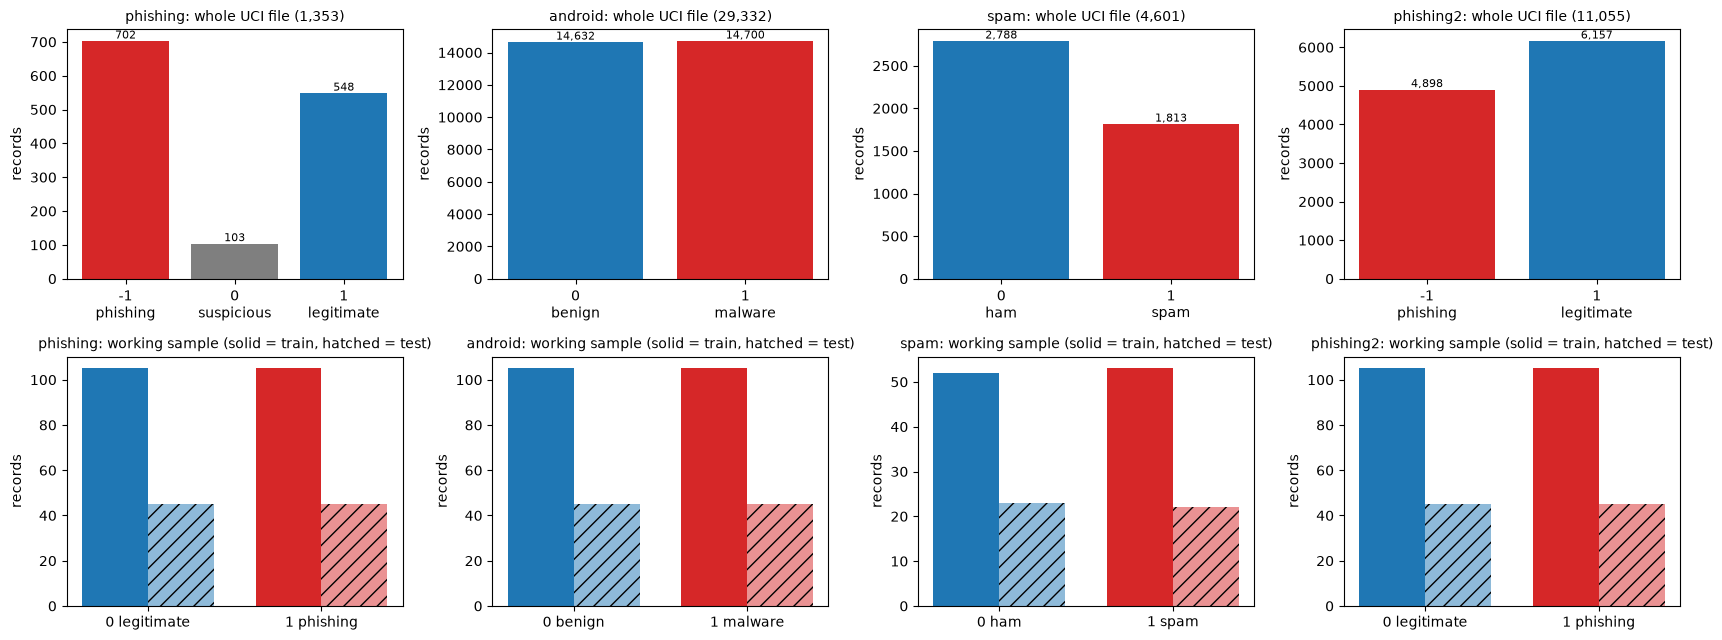

In [6]:
for key, d in D.items():
    spec, df = d["spec"], RAW[key]
    print("=" * 100)
    print(f"{spec['title']} (UCI {spec['uci_id']}): shape {df.shape[0]:,} x {df.shape[1]} ({df.shape[1]-1} features + label)")
    print("features used by the paper / this notebook (%d):" % len(d["cols"]), d["cols"])
    print("all feature names:", [c for c in d["feat_all"]][:12], "..." if len(d["feat_all"]) > 12 else "")
    lab = df[spec["label"]].value_counts().sort_index()
    print("original label values and counts:", {f"{k} ({spec['names'].get(k, '?')})": int(v) for k, v in lab.items()})
    print(f"working sample: {len(d['tr_idx'])} train + {len(d['te_idx'])} test; classes in train {np.bincount(d['y_tr']).tolist()}, in test {np.bincount(d['y_te']).tolist()}")
    print("missing values in the used columns:", int(df[d["cols"]].isnull().sum().sum()))

fig, axes = plt.subplots(2, 4, figsize=(17, 6.5))
for j, (key, d) in enumerate(D.items()):
    spec, df = d["spec"], RAW[key]
    lab = df[spec["label"]].value_counts().sort_index()
    cols = ["tab:red" if k in spec["attack"] else "tab:blue" if k in spec["benign"] else "tab:gray" for k in lab.index]
    axes[0, j].bar([f"{k}\n{spec['names'].get(k, '?')}" for k in lab.index], lab.values, color=cols)
    axes[0, j].set_title(f"{key}: whole UCI file ({len(df):,})", fontsize=10); axes[0, j].set_ylabel("records")
    for r, v in zip(axes[0, j].patches, lab.values): axes[0, j].annotate(f"{v:,}", (r.get_x() + r.get_width()/2, v), ha="center", va="bottom", fontsize=8)
    ytr, yte = np.bincount(d["y_tr"], minlength=2), np.bincount(d["y_te"], minlength=2)
    xs = np.arange(2); w = 0.38
    axes[1, j].bar(xs - w/2, ytr, w, label="train", color=["tab:blue", "tab:red"]); axes[1, j].bar(xs + w/2, yte, w, label="test", color=["tab:blue", "tab:red"], alpha=0.5, hatch="//")
    axes[1, j].set_xticks(xs); axes[1, j].set_xticklabels([f"0 {spec['benign_name']}", f"1 {spec['attack_name']}"])
    axes[1, j].set_title(f"{key}: working sample (solid = train, hatched = test)", fontsize=10); axes[1, j].set_ylabel("records")
plt.tight_layout(); plt.show()

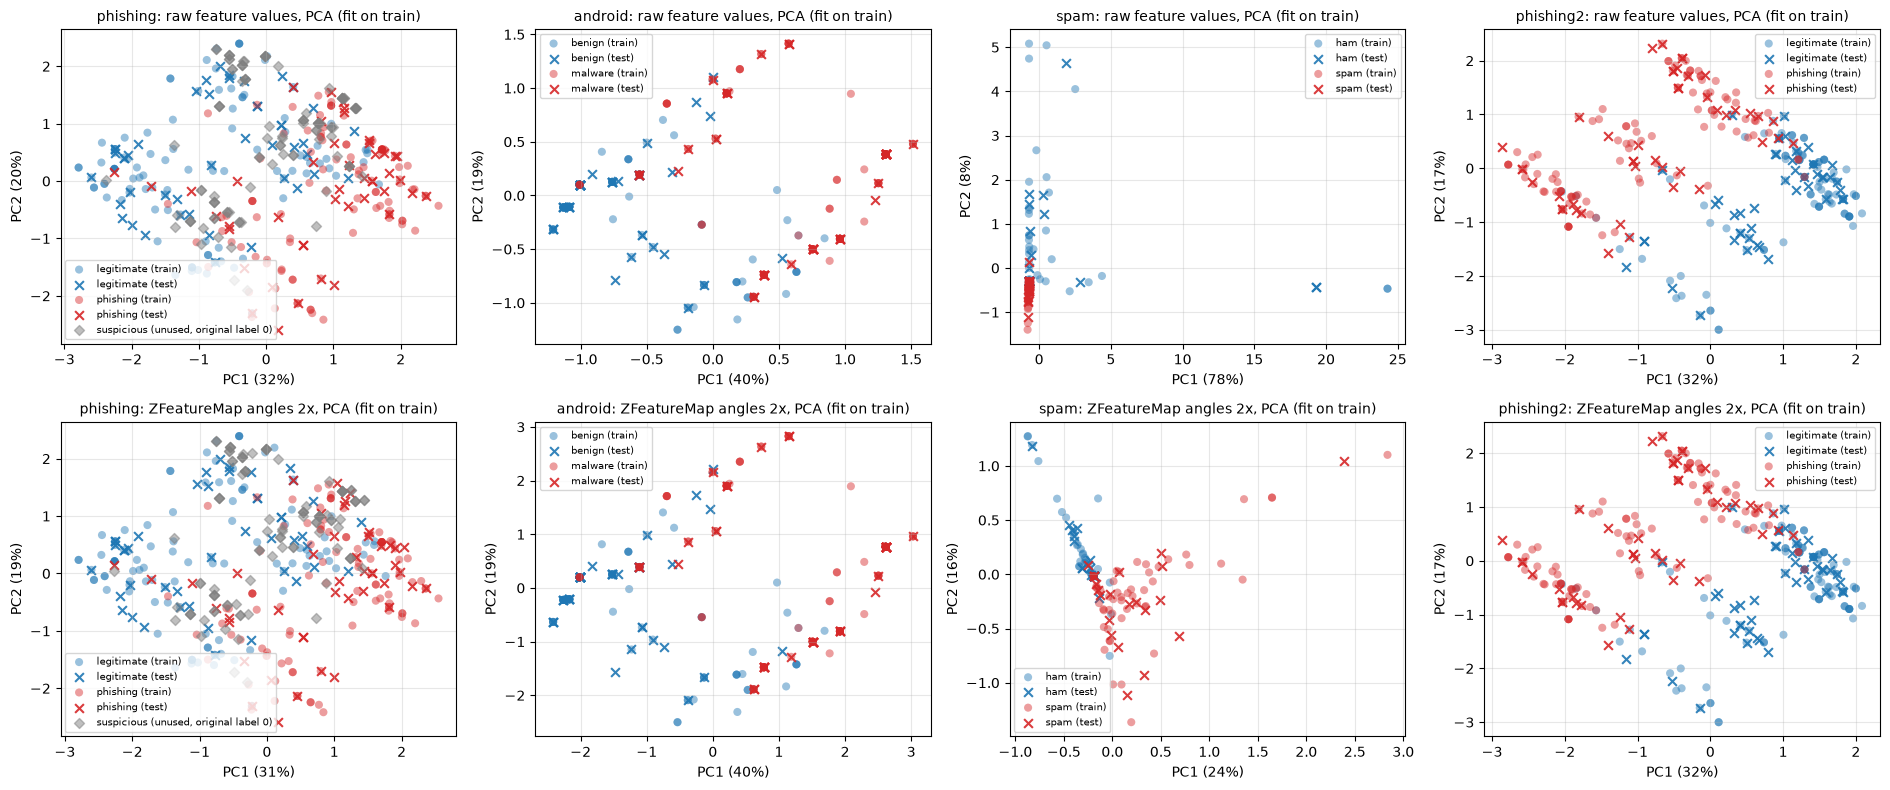

In [7]:
def pca_scatter(ax, d, angles, title):
    """Scatter of real records: PCA fitted on the training split; colour = ground-truth label (train filled, test crosses)."""
    spec, df = d["spec"], RAW[d["key"]]
    f = (lambda X: 2.0 * X) if angles else (lambda X: X)
    Xtr, Xte = f(d["X_tr"]) if angles else d["raw_tr"].astype(float), f(d["X_te"]) if angles else d["raw_te"].astype(float)
    pca = PCA(n_components=2, random_state=SEED).fit(Xtr)
    Ztr, Zte = pca.transform(Xtr), pca.transform(Xte)
    for cls, color, nm in ((0, "tab:blue", spec["benign_name"]), (1, "tab:red", spec["attack_name"])):
        ax.scatter(*Ztr[d["y_tr"] == cls].T, c=color, s=34, alpha=0.45, edgecolors="none", label=f"{nm} (train)")
        ax.scatter(*Zte[d["y_te"] == cls].T, c=color, s=40, alpha=0.9, marker="x", label=f"{nm} (test)")
    other = df.index[~df[spec["label"]].isin(spec["attack"] + spec["benign"])]
    if len(other):                                           # records with a third original label (phishing: "suspicious")
        Xo = df.loc[other, d["cols"]].values.astype(float)
        if angles: Xo = 2.0 * np.clip(MinMaxScaler().fit(d["raw_tr"]).transform(Xo), 0, 1)
        ax.scatter(*pca.transform(Xo).T, c="gray", s=26, alpha=0.5, marker="D", label=f"{spec['names'][0]} (unused, original label 0)")
    ax.set_title(title, fontsize=10); ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
    ax.grid(alpha=0.3); ax.legend(fontsize=7, loc="best")

fig, axes = plt.subplots(2, 4, figsize=(19, 8))
for j, (key, d) in enumerate(D.items()):
    pca_scatter(axes[0, j], d, False, f"{key}: raw feature values, PCA (fit on train)")
    pca_scatter(axes[1, j], d, True,  f"{key}: ZFeatureMap angles 2x, PCA (fit on train)")
plt.tight_layout(); plt.show()

## 3. Classical baseline (the paper's Table 7 and Figs. 8-10)

The paper trains scikit-learn's `SVC` "with a default parameterisation" on each reduced dataset and reports training and test accuracy. We do the
same on exactly the inputs the VQC will see (same columns, same scaling, same split), report the confusion matrices of Figs. 8-10, and add what the
paper does not give: a random forest, the SVC on **all** features of the working sample, the SVC on columns chosen by ANOVA **on the training split only**, and
the spread over five independent resamples. A test set of 90 records (45 for spam) cannot resolve differences below about 0.05, so the repeats matter.

,svc_train,svc_test,paper_train,paper_test,rf_test,svc_qubit0_feature_only_test,svc_all_features_test,svc_anova_train_only_test,anova_overlap_with_paper_cols,svc_test_resample_mean,svc_test_resample_std
dataset,,,,,,,,,,,
phishing,0.938,0.922,0.92,0.93,0.933,0.867,0.922,0.922,9/9,0.907,0.019
android,0.924,0.933,0.99,0.98,0.967,0.667,0.967,0.933,8/9,0.898,0.037
spam,0.914,0.822,0.93,0.87,0.889,0.622,0.889,0.800,4/10,0.844,0.047
phishing2,0.943,0.900,0.97,0.87,0.956,0.756,0.900,0.889,8/9,0.918,0.025


For phishing2 the 'paper' columns are Table 15's classical SVC (0.97 / 0.87).


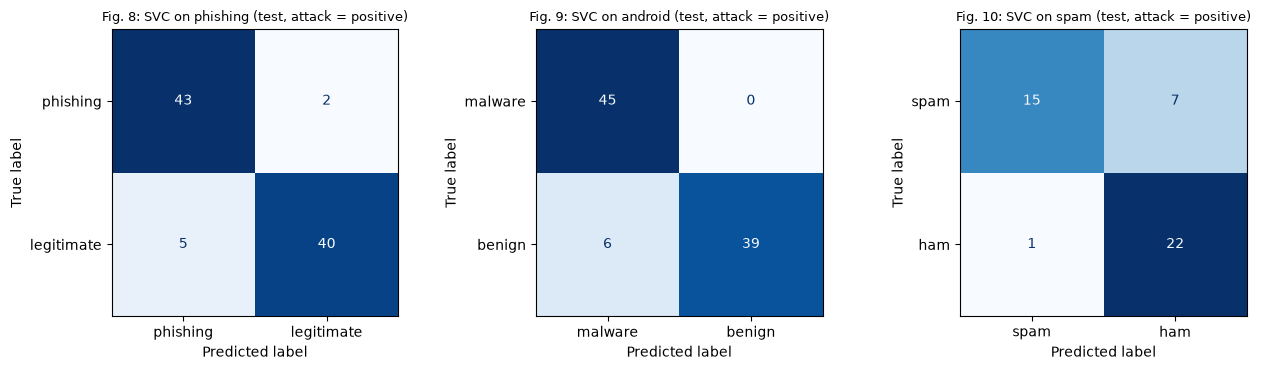

In [8]:
def acc_pair(model, d):
    model.fit(d["X_tr"], d["y_tr"])
    return accuracy_score(d["y_tr"], model.predict(d["X_tr"])), accuracy_score(d["y_te"], model.predict(d["X_te"]))

PAPER_T7 = {"phishing": (0.92, 0.93), "android": (0.99, 0.98), "spam": (0.93, 0.87)}
rows = []
for key in ("phishing", "android", "spam", "phishing2"):
    d = D[key]
    tr, te = acc_pair(SVC(), d)                                                # paper: default SVC
    rf_tr, rf_te = acc_pair(RandomForestClassifier(n_estimators=200, random_state=SEED), d)
    d_all = prepare(key, cols="all"); a_tr, a_te = acc_pair(SVC(), d_all)
    d_an = prepare(key, cols="anova"); n_tr, n_te = acc_pair(SVC(), d_an)
    reps = []
    for r in range(N_BASELINE_REPEATS):
        dr = prepare(key, seed=SEED + 1 + r); reps.append(acc_pair(SVC(), dr)[1])
    d0 = dict(d, X_tr=d["X_tr"][:, :1], X_te=d["X_te"][:, :1]); f0_tr, f0_te = acc_pair(SVC(), d0)      # only the feature that sits on qubit 0
    overlap = len(set(d["paper_cols"]) & set(d["anova_cols"]))
    pt = PAPER_T7.get(key, (0.97, 0.87))                                         # phishing2: Table 15
    rows.append(dict(dataset=key, svc_train=round(tr, 3), svc_test=round(te, 3), paper_train=pt[0], paper_test=pt[1],
                     rf_test=round(rf_te, 3), svc_qubit0_feature_only_test=round(f0_te, 3), svc_all_features_test=round(a_te, 3), svc_anova_train_only_test=round(n_te, 3),
                     anova_overlap_with_paper_cols=f"{overlap}/{len(d['paper_cols'])}", svc_test_resample_mean=round(np.mean(reps), 3), svc_test_resample_std=round(np.std(reps), 3)))
baseline_df = pd.DataFrame(rows).set_index("dataset")
display(baseline_df)
print("For phishing2 the 'paper' columns are Table 15's classical SVC (0.97 / 0.87).")
SVC_RES = {k: (baseline_df.loc[k, "svc_train"], baseline_df.loc[k, "svc_test"]) for k in baseline_df.index}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, key, fig_no in zip(axes, ("phishing", "android", "spam"), (8, 9, 10)):
    d = D[key]; m = SVC().fit(d["X_tr"], d["y_tr"])
    ConfusionMatrixDisplay(confusion_matrix(d["y_te"], m.predict(d["X_te"]), labels=[1, 0]), display_labels=[D[key]["spec"]["attack_name"], D[key]["spec"]["benign_name"]]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Fig. {fig_no}: SVC on {key} (test, attack = positive)", fontsize=9)
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

Every VQC in the paper has the same shape: **feature map -> ansatz -> measurement of all qubits**, with one qubit per feature
(9 qubits for Phishing and Android, 10 for Spam). The class is the bit-string integer modulo 2, i.e. the measured value of qubit 0 (Qiskit's
`VQC` default; the docstring calls it parity, but for two classes `x % 2` is the lowest bit).

* **Feature map** `z_feature_map(n, reps=2)`: Hadamard then P(2 x_i) on every qubit, twice (the paper's Fig. 2). It creates no entanglement.
* **`RealAmplitudes`**: RY(theta) on every qubit, `reps + 1` layers, with the entanglement removed as the paper says. With a product feature map
  *and* no entangling gate the whole circuit is a product state, so only the rotations of qubit 0 can influence the read-out (see the critical reading).
* **`EfficientSU2`**: RY and RZ on every qubit and a CNOT chain between layers (Qiskit's default `reverse_linear`), `reps + 1` rotation layers.
* **`ExcitationPreserving`**: RZ layers and an XX+YY ("iswap-type") interaction on **every pair** of qubits (default `full` entanglement): hence the
  "too large to be represented" remark in the paper.

The cell draws the circuit the `VQC` object actually holds (feature map composed with ansatz, plus the final measurements), one drawing per
distinct architecture and qubit count, and prints qubits, depth (compiled to `u`/`cx`/`rxx`/`ryy`-free basis `u, cx`) and the number of trainable parameters.
`ANSATZ_REPS` is the assumption the paper leaves open (it only shows the 9-qubit figures, whose repetition count cannot be read from the text).

--- 9 qubits (phishing / android / phishing2): ZFeatureMap(reps=2) + RealAmplitudes(reps=3) + measure_all ---


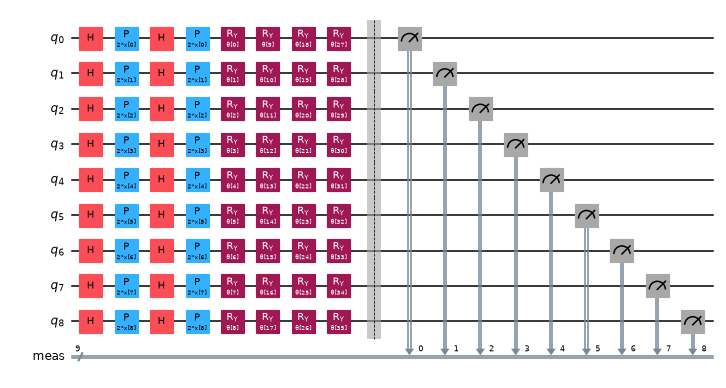

--- 9 qubits (phishing / android / phishing2): ZFeatureMap(reps=2) + EfficientSU2(reps=3) + measure_all ---


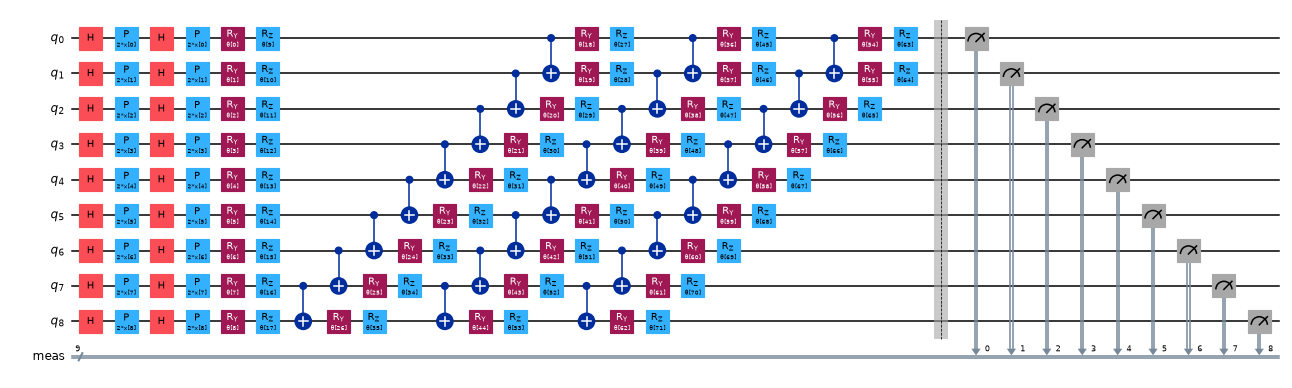

--- 9 qubits (phishing / android / phishing2): ZFeatureMap(reps=2) + ExcitationPreserving(reps=3) + measure_all ---


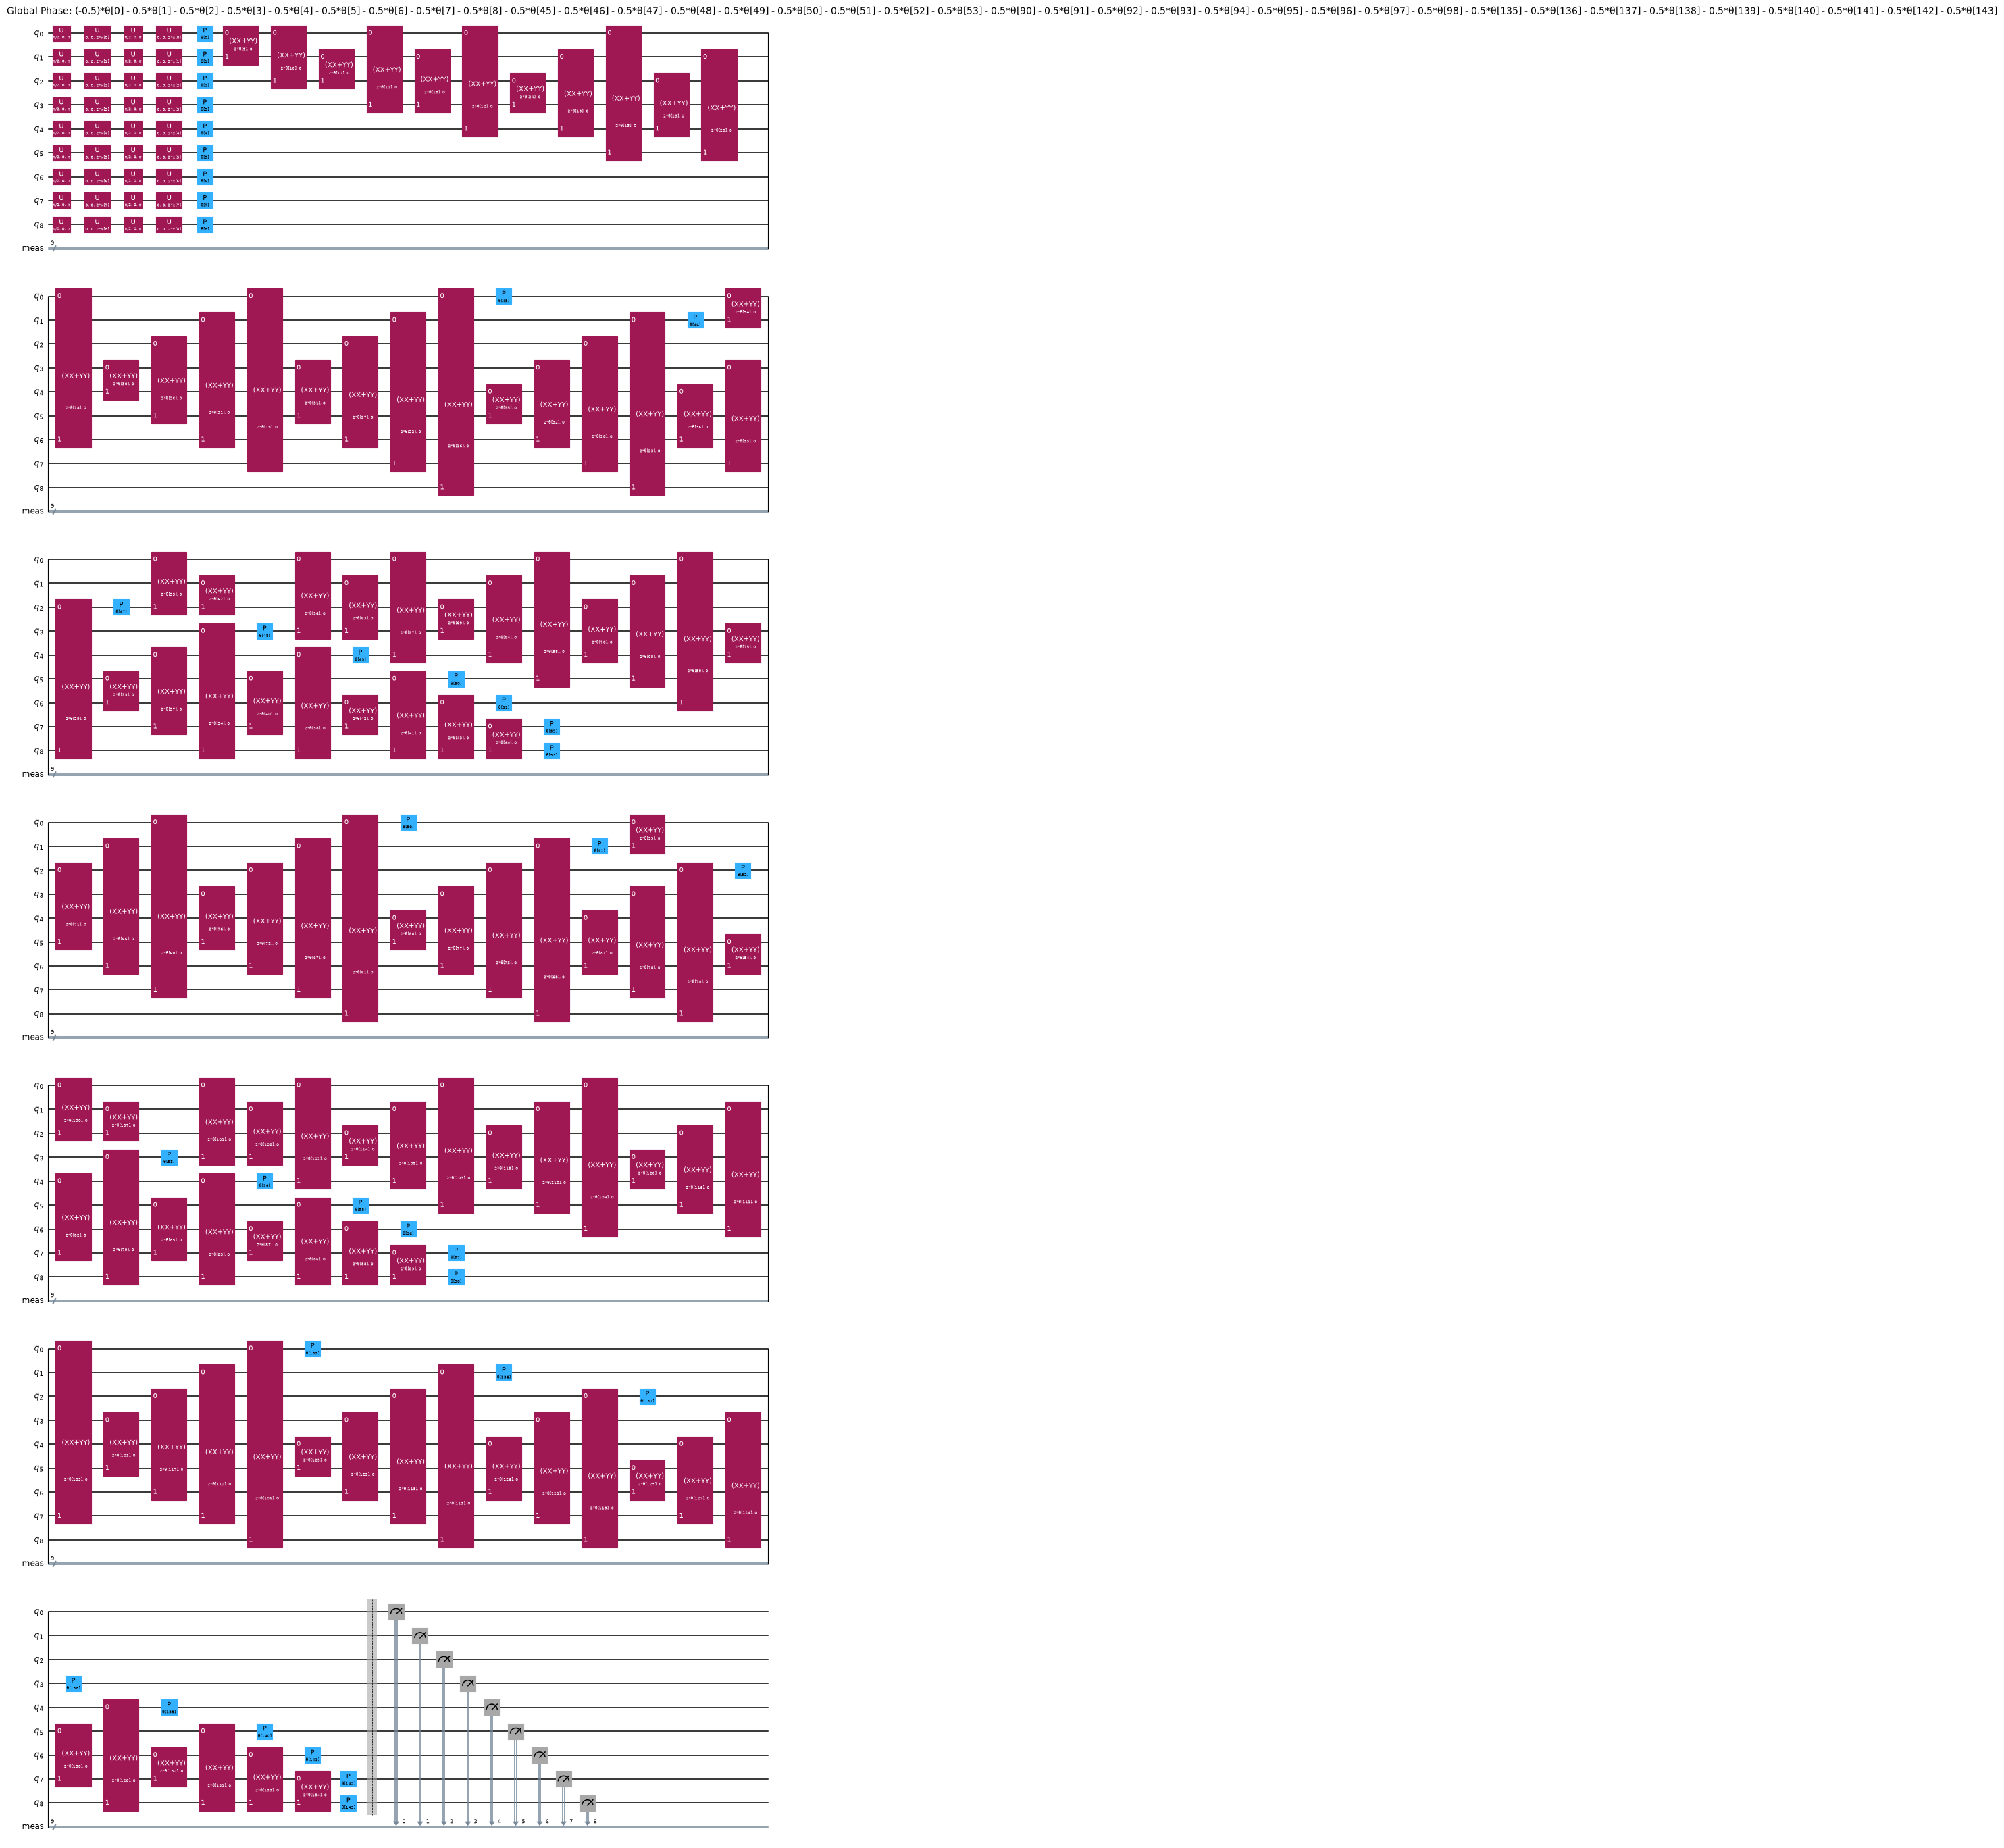

--- 10 qubits (spam): ZFeatureMap(reps=2) + RealAmplitudes(reps=3) + measure_all ---


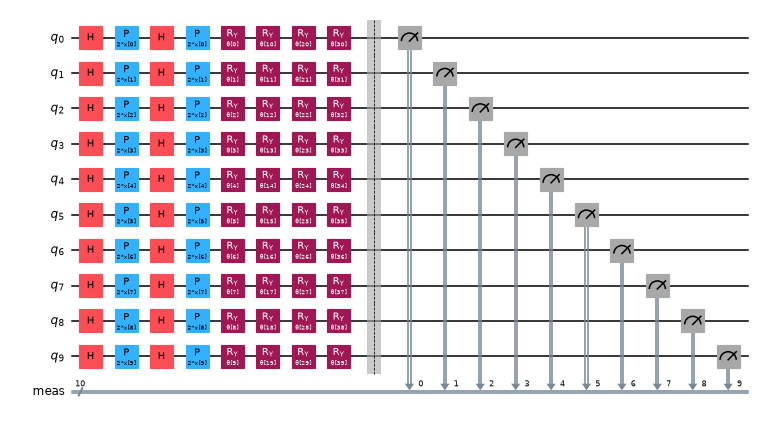

--- 10 qubits (spam): ZFeatureMap(reps=2) + EfficientSU2(reps=3) + measure_all ---


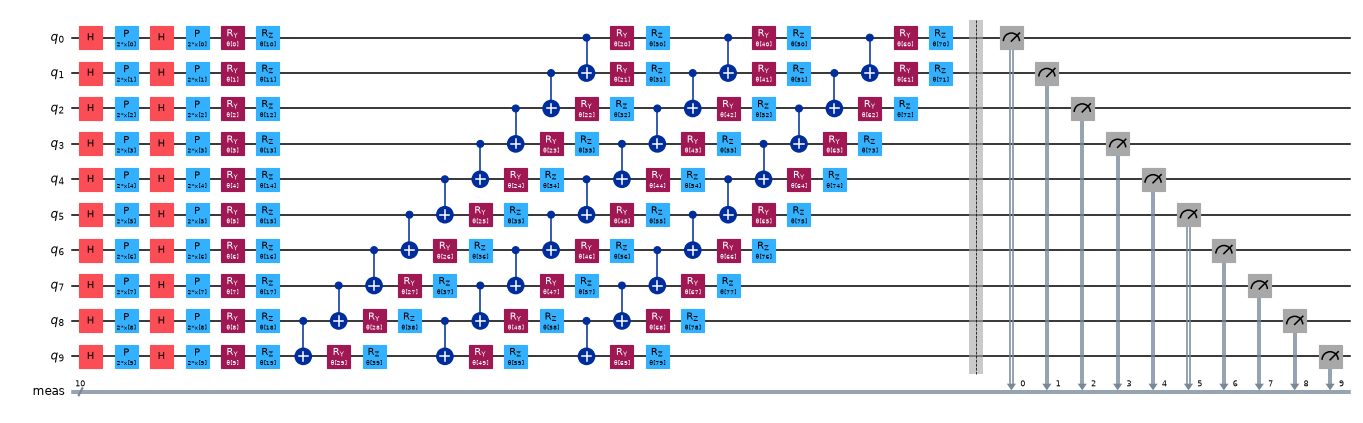

--- 10 qubits (spam): ZFeatureMap(reps=2) + ExcitationPreserving(reps=3) + measure_all ---


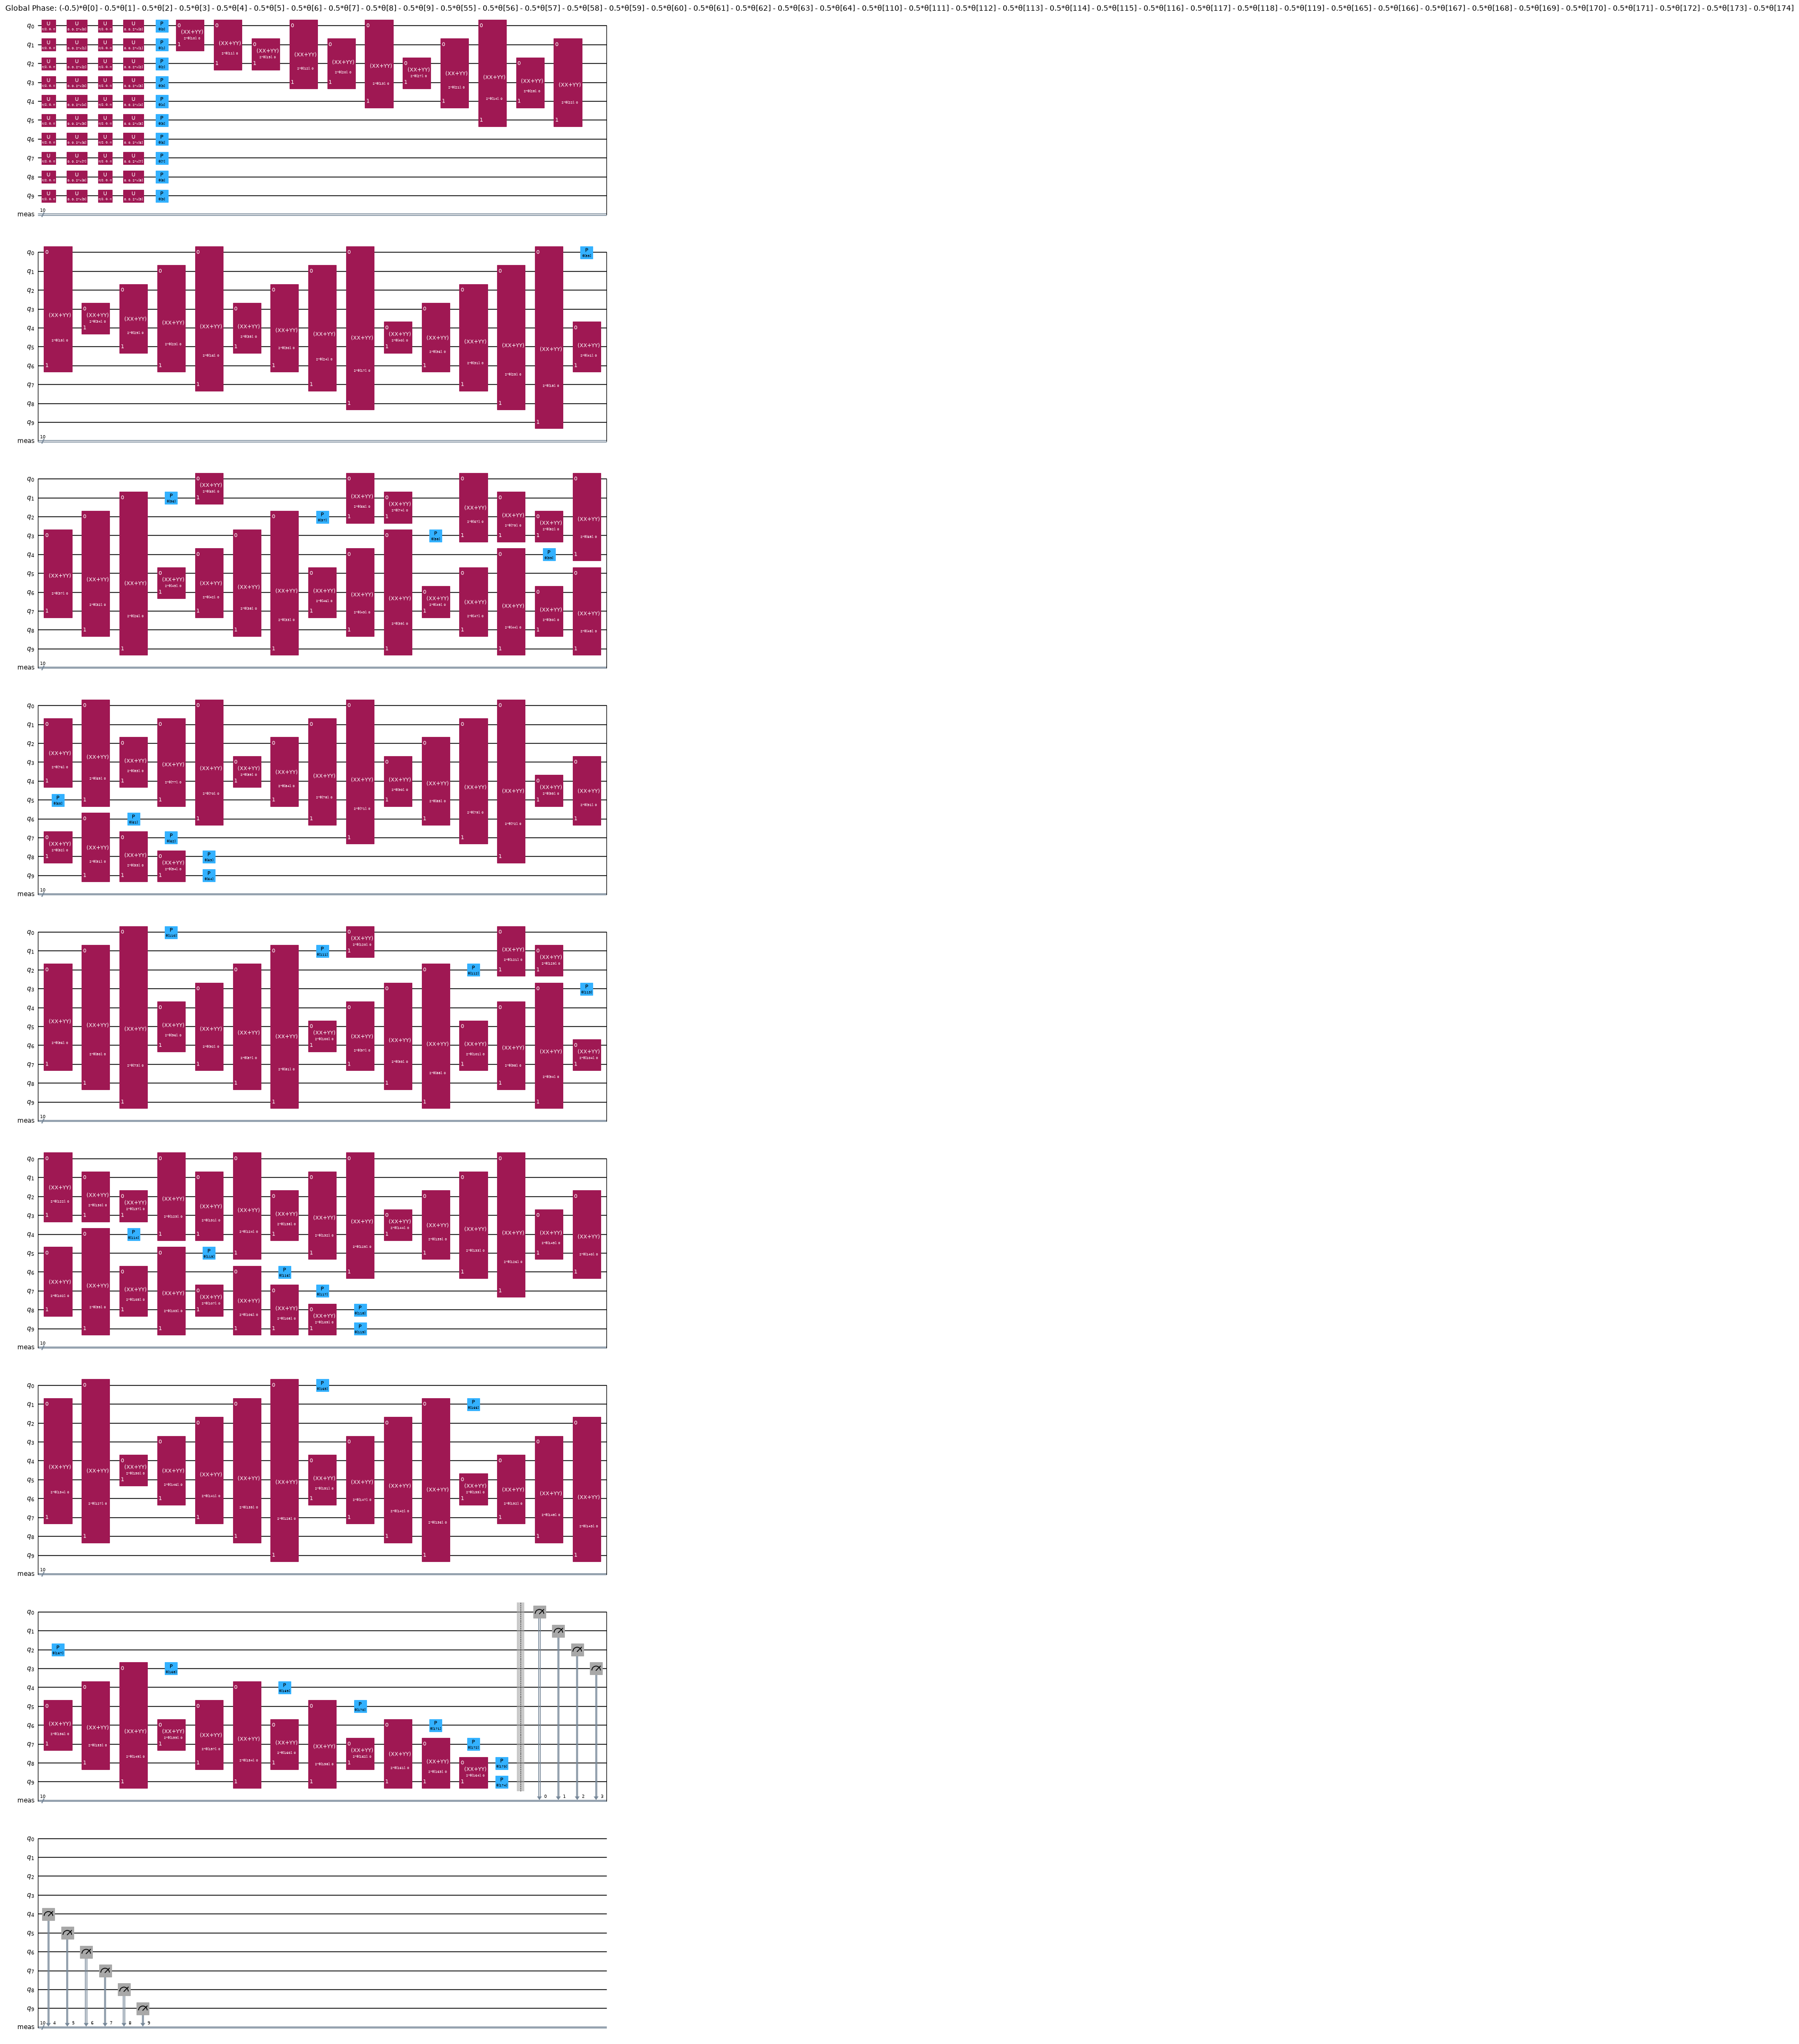

,qubits,used_for,ansatz,depth_compiled_u_cx,cx_gates,trainable_parameters,input_parameters
0,9,phishing / android / phishing2,RealAmplitudes,8,0,36,9
1,9,phishing / android / phishing2,EfficientSU2,24,24,72,9
2,9,phishing / android / phishing2,ExcitationPreserving,285,216,144,9
3,10,spam,RealAmplitudes,8,0,40,10
4,10,spam,EfficientSU2,25,27,80,10
5,10,spam,ExcitationPreserving,319,270,175,10


In [9]:
def make_ansatz(name, n, reps=ANSATZ_REPS):
    if name == "RealAmplitudes":        return real_amplitudes(n, reps=reps, entanglement=RA_ENTANGLEMENT)     # CHOICE: no entanglement (paper)
    if name == "EfficientSU2":          return efficient_su2(n, reps=reps)                                     # default reverse_linear CX chain
    if name == "ExcitationPreserving":  return excitation_preserving(n, reps=reps)                             # default: full entanglement, iswap mode
    raise ValueError(name)
ANSATZE = ["RealAmplitudes", "EfficientSU2", "ExcitationPreserving"]
OPTIMISERS = ["COBYLA", "POWELL", "SLSQP"]

from qiskit import transpile
circ_rows = []
for n in (9, 10):
    who = "phishing / android / phishing2" if n == 9 else "spam"
    for name in ANSATZE:
        vqc = VQC(feature_map=z_feature_map(n, reps=ZFM_REPS), ansatz=make_ansatz(name, n), optimizer=COBYLA(maxiter=1), sampler=QMLSampler())
        exec_circ = vqc.circuit.copy(); exec_circ.measure_all()                          # what the sampler runs: data + ansatz + measurement
        basis = transpile(exec_circ.remove_final_measurements(inplace=False), basis_gates=["u", "cx"], optimization_level=0)
        circ_rows.append(dict(qubits=n, used_for=who, ansatz=name, depth_compiled_u_cx=basis.depth(), cx_gates=basis.count_ops().get("cx", 0),
                              trainable_parameters=vqc.ansatz.num_parameters, input_parameters=vqc.feature_map.num_parameters))
        print(f"--- {n} qubits ({who}): ZFeatureMap(reps={ZFM_REPS}) + {name}(reps={ANSATZ_REPS}) + measure_all ---")
        drawing = exec_circ.decompose() if name == "ExcitationPreserving" else exec_circ
        display(drawing.draw("mpl", fold=40 if name != "ExcitationPreserving" else 30, scale=0.55))
display(pd.DataFrame(circ_rows))

## 4. Why a custom simulator, and how it is proved equal to Qiskit

`VQC.fit` evaluates the loss by running one `Sampler` job per training record (about 0.1 s per 9-qubit circuit on a laptop). `COBYLA` needs 100
evaluations, `POWELL` thousands, and `SLSQP` needs a gradient that the parameter-shift rule gets from 2 x (number of parameters) circuits per record.
That is why the paper's cells took hours. The circuits are small, though: a 9-qubit state has only 512 amplitudes. The class below stores the whole
training batch as an array `psi[N, 512]`, applies each gate layer to all records at once, and differentiates with the **adjoint method** (one backward sweep gives
all weight gradients exactly). The feature map is a product state and is written in closed form.

It is a plain NumPy file of about 170 lines (the next cell). It supports exactly the gates that occur in the three ansaetze (`ry`, `rz`, `cx` and
Qiskit's XX+YY `Interaction` block) and reads the gate list **from the Qiskit circuit object** that is drawn above, so there is one source of truth.
Section 5 asserts equivalence before anything is trained.

In [10]:
# ------- exact batch simulator with adjoint gradient (written for this notebook; read from the Qiskit circuit object) -------
import numpy as np

# ---------------------------------------------------------------------------------------------
# A small exact simulator for "feature map + ansatz" circuits, written for speed on a whole batch.
# States are arrays psi[N, 2**n]; qubit q is bit q of the basis-state index (Qiskit little endian).
# ---------------------------------------------------------------------------------------------
def m_ry(t):  c, s = np.cos(t / 2), np.sin(t / 2); return np.array([[c, -s], [s, c]], dtype=complex)
def m_rz(t):  return np.array([[np.exp(-0.5j * t), 0], [0, np.exp(0.5j * t)]], dtype=complex)

def _rot(a, n):
    """Cyclic bit rotation of the index: the least significant qubit becomes the most significant one."""
    return np.ascontiguousarray(a.reshape(a.shape[0], 2 ** (n - 1), 2).transpose(0, 2, 1)).reshape(a.shape[0], -1)

def _lsb(a, M):
    """Apply the 2x2 matrix M to the least significant qubit (one BLAS call on a (N*2**(n-1), 2) matrix)."""
    return (a.reshape(-1, 2) @ M.T).reshape(a.shape)

def _view2(psi, a, b, n):
    hi, lo = max(a, b), min(a, b)
    return psi.reshape(psi.shape[0], 2 ** (n - 1 - hi), 2, 2 ** (hi - lo - 1), 2, 2 ** lo)

def apply_xxyy(psi, theta, a, b, n):
    """exp(-i theta/2 (XX+YY)) on qubits a, b: identity on |00>,|11>, a rotation by theta inside span{|01>,|10>}."""
    v = _view2(psi, a, b, n)
    c, s = np.cos(theta), np.sin(theta)
    out = v.copy()
    x01, x10 = v[:, :, 0, :, 1, :], v[:, :, 1, :, 0, :]
    out[:, :, 0, :, 1, :] = c * x01 - 1j * s * x10
    out[:, :, 1, :, 0, :] = -1j * s * x01 + c * x10
    return out.reshape(psi.shape)

def xxyy_generator(psi, a, b, n):
    """(XX+YY) |psi>, the generator of the Interaction block."""
    v = _view2(psi, a, b, n)
    out = np.zeros_like(v)
    out[:, :, 0, :, 1, :] = 2 * v[:, :, 1, :, 0, :]
    out[:, :, 1, :, 0, :] = 2 * v[:, :, 0, :, 1, :]
    return out.reshape(psi.shape)

class Ansatz:
    """Gate list of a Qiskit ansatz (ry, rz, cx, Interaction = XX+YY block), grouped into layers so a batch runs in a few ms."""
    def __init__(self, circuit):
        self.n = n = circuit.num_qubits
        params = list(circuit.parameters)
        pidx = {p: i for i, p in enumerate(params)}
        self.num_weights = len(params)
        raw = []
        for inst in circuit.data:
            name = inst.operation.name
            qs = [circuit.find_bit(b).index for b in inst.qubits]
            if name == "cx":
                raw.append(("cx", qs, None, 1.0)); continue
            expr = inst.operation.params[0]
            ps = list(expr.parameters) if hasattr(expr, "parameters") else []
            assert len(ps) == 1, f"gate {name} must depend on exactly one weight"
            coef = float(expr.bind({ps[0]: 1.0})) if expr is not ps[0] else 1.0
            raw.append(({"ry": "ry", "rz": "rz", "Interaction": "xxyy"}[name], qs, pidx[ps[0]], coef))
        self.stages = []          # ("layer", kind, {qubit: (weight idx, coef)}) | ("perm", f) | ("xxyy", (a, b), idx, coef)
        for kind, qs, i, c in raw:
            last = self.stages[-1] if self.stages else None
            if kind in ("ry", "rz"):
                if last and last[0] == "layer" and last[1] == kind and qs[0] not in last[2]:
                    last[2][qs[0]] = (i, c)
                else:
                    self.stages.append(("layer", kind, {qs[0]: (i, c)}))
            elif kind == "cx":
                f = np.arange(2 ** n)
                if not (last and last[0] == "perm"):
                    self.stages.append(("perm", f))
                f = self.stages[-1][1]
                self.stages[-1] = ("perm", f ^ (((f >> qs[0]) & 1) << qs[1]))      # follow the CNOT on the basis-state labels
            else:
                self.stages.append(("xxyy", tuple(qs), i, c))
        self.stages = [(s[0], np.argsort(s[1]), s[1]) if s[0] == "perm" else s for s in self.stages]

    def forward(self, psi, w):
        n = self.n
        for st in self.stages:
            if st[0] == "layer":
                _, kind, qd = st
                mk = m_ry if kind == "ry" else m_rz
                for q in range(n):
                    if q in qd:
                        i, c = qd[q]; psi = _lsb(psi, mk(c * w[i]))
                    psi = _rot(psi, n)
            elif st[0] == "perm":
                psi = psi[:, st[1]]
            else:
                _, (a, b), i, c = st; psi = apply_xxyy(psi, c * w[i], a, b, n)
        return psi

    def backward(self, psi, chi, w):
        """Adjoint differentiation. chi = dL/d conj(psi_final) (Wirtinger); returns dL/dw (psi = final state)."""
        n = self.n; g = np.zeros(self.num_weights)
        for st in reversed(self.stages):
            if st[0] == "layer":
                _, kind, qd = st
                mk = m_ry if kind == "ry" else m_rz
                for q in range(n):
                    if q in qd:
                        i, c = qd[q]
                        x, y = psi.reshape(-1, 2), chi.reshape(-1, 2)
                        if kind == "ry":     # <chi| Y |psi> with Y = [[0,-i],[i,0]]
                            val = np.vdot(y[:, 0], -1j * x[:, 1]) + np.vdot(y[:, 1], 1j * x[:, 0])
                        else:                # <chi| Z |psi>
                            val = np.vdot(y[:, 0], x[:, 0]) - np.vdot(y[:, 1], x[:, 1])
                        g[i] += c * val.imag
                        Md = mk(-c * w[i])   # undo the gate
                        psi, chi = _lsb(psi, Md), _lsb(chi, Md)
                    psi, chi = _rot(psi, n), _rot(chi, n)
            elif st[0] == "perm":
                psi, chi = psi[:, st[2]], chi[:, st[2]]
            else:
                _, (a, b), i, c = st
                g[i] += c * np.vdot(chi, xxyy_generator(psi, a, b, n)).imag
                psi, chi = apply_xxyy(psi, -c * w[i], a, b, n), apply_xxyy(chi, -c * w[i], a, b, n)
        return g

def zfm_states(X, reps=2):
    """Exact states after qiskit's z_feature_map(n, reps): a product state; qubit q carries feature X[:, q]."""
    N, n = X.shape
    H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
    v = np.zeros((N, n, 2), dtype=complex); v[..., 0] = 1.0
    for _ in range(reps):
        v = np.einsum("ab,nqb->nqa", H, v)
        v[..., 1] *= np.exp(2j * X)                      # P(2 x): phase on |1>
    psi = v[:, n - 1, :]                                  # most significant qubit first
    for q in range(n - 2, -1, -1):
        psi = (psi[:, :, None] * v[:, q, None, :]).reshape(N, -1)
    return psi

class FastVQC:
    """Exactly what qiskit-machine-learning's VQC computes (class = bit-string integer mod 2, base-2 cross entropy, mean over samples)
    but with the whole batch simulated at once and an adjoint gradient."""
    def __init__(self, n_qubits, ansatz_circuit, zfm_reps=2):
        self.n = n_qubits; self.ans = Ansatz(ansatz_circuit); self.reps = zfm_reps
        self.num_weights = self.ans.num_weights
        self.nfev = 0; self.njev = 0
    def set_data(self, X, y):
        self.psi0 = zfm_states(X, self.reps); self.y = np.asarray(y).astype(int); self.N = len(y)
    def probs(self, w, psi0=None):
        psi = self.ans.forward(self.psi0 if psi0 is None else psi0, w)
        p1 = (np.abs(psi[:, 1::2]) ** 2).sum(axis=1)       # bit-string integer x -> class x % 2
        return np.stack([1 - p1, p1], axis=1), psi
    def loss(self, w):
        self.nfev += 1
        P, _ = self.probs(w)
        return float(np.mean(-np.log2(np.clip(P[np.arange(self.N), self.y], 1e-10, None))))
    def grad(self, w):
        self.njev += 1
        P, psi = self.probs(w)
        py = P[np.arange(self.N), self.y]
        scale = -(py > 1e-10).astype(float) / (np.clip(py, 1e-10, None) * self.N * np.log(2))   # dL/dP_y per sample
        chi = np.zeros_like(psi)
        mask = (np.arange(psi.shape[1])[None, :] % 2) == self.y[:, None]
        chi[mask] = (psi * scale[:, None])[mask]                                  # dL/d conj(psi) = dL/dP_y * psi on the matching parity
        return self.ans.backward(psi, chi, w)
    def predict(self, X, w):
        P, _ = self.probs(w, zfm_states(X, self.reps))
        return P.argmax(axis=1)

## 5. Equivalence checks (must pass before training)

1. **Statevectors.** For every ansatz and both widths, the simulated state of a record equals `Statevector` of the drawn Qiskit circuit (feature map composed with ansatz,
   random weights) to 1e-10.
2. **Qiskit's own `VQC`.** The class probabilities of the `SamplerQNN` that `VQC` builds equal the simulator's (9 qubits, the real depth, two records), and the loss gradient
   built from Qiskit's parameter-shift `backward` equals the simulator's adjoint gradient (5 qubits, reps = 1, for all three ansaetze; 9 qubits would make Qiskit's run take minutes).
3. **Finite differences.** The adjoint gradient equals a central finite difference on the simulator's loss for random weights (real 9-qubit circuits).
4. **End to end.** A real `VQC.fit` with `COBYLA(maxiter=30)` (5 qubits, `EfficientSU2`, same initial point) and the simulator driven by the same `COBYLA` object follow the same loss
   trajectory evaluation by evaluation.

In [11]:
t0 = time.time()
rs = np.random.default_rng(SEED + 7)
# 1. statevectors of the drawn circuits
for n in (9, 10):
    fm = z_feature_map(n, reps=ZFM_REPS)
    for name in ANSATZE:
        ans = make_ansatz(name, n); m = FastVQC(n, ans, ZFM_REPS)
        Xc = rs.random((2, n)); w = rs.random(m.num_weights) * 2 * np.pi
        m.set_data(Xc, [0, 1])
        for i in range(2):
            qc = QuantumCircuit(n); qc.compose(fm.assign_parameters(Xc[i]), inplace=True); qc.compose(ans.assign_parameters(w), inplace=True)
            assert np.allclose(Statevector(qc).data, m.ans.forward(m.psi0[i:i+1], w)[0], atol=1e-10), (n, name)
print("1. statevectors of FeatureMap+ansatz agree to 1e-10 for 3 ansaetze x {9, 10} qubits")

# 3. finite differences
for name in ANSATZE:
    n = 9; m = FastVQC(n, make_ansatz(name, n), ZFM_REPS); Xc = rs.random((6, n)); m.set_data(Xc, [0, 1, 0, 1, 1, 0])
    w = rs.random(m.num_weights) * 2 * np.pi; g = m.grad(w)
    for j in rs.choice(m.num_weights, 4, replace=False):
        e = 1e-6; wp, wm = w.copy(), w.copy(); wp[j] += e; wm[j] -= e
        assert abs((m.loss(wp) - m.loss(wm)) / (2 * e) - g[j]) < 1e-5, (name, j)
print("3. adjoint gradient equals central finite differences (3 ansaetze, 4 random weights each)")

# 2. against qiskit-machine-learning's VQC. Probabilities at the real 9-qubit width and depth; parameter-shift gradient on 5 qubits, reps = 1 (keeps Qiskit's run short)
for n, reps, with_grad in ((9, ANSATZ_REPS, False), (5, 1, True)):
    fm = z_feature_map(n, reps=ZFM_REPS); Xc = rs.random((2, n)); yc = np.array([0, 1])
    for name in ANSATZE:
        ans = make_ansatz(name, n, reps=reps)
        vqc = VQC(feature_map=fm, ansatz=ans, optimizer=COBYLA(maxiter=1), sampler=QMLSampler())
        if with_grad:
            vqc.fit(Xc, yc); qnn = vqc.neural_network                 # the network VQC builds internally
        else:                                                         # same network, built directly (no training needed for a forward pass)
            from qiskit_machine_learning.neural_networks import SamplerQNN
            qnn = SamplerQNN(sampler=QMLSampler(), circuit=vqc.circuit, input_params=fm.parameters, weight_params=ans.parameters,
                             interpret=vqc.interpret, output_shape=2, input_gradients=False)
        w = rs.random(ans.num_parameters) * 3
        P = qnn.forward(Xc, w); m = FastVQC(n, ans, ZFM_REPS); m.set_data(Xc, yc); Pm, _ = m.probs(w)
        msg = f"2. {n} qubits reps={reps} {name:21s} max|dP| = {np.abs(P - Pm).max():.1e}"
        assert np.abs(P - Pm).max() < 1e-8
        if with_grad:
            _, wg = qnn.backward(Xc, w); py = Pm[np.arange(2), yc]
            g_qiskit = np.einsum("n,np->p", -1 / (py * 2 * np.log(2)), wg[np.arange(2), yc, :])
            msg += f"   max|d grad| = {np.abs(g_qiskit - m.grad(w)).max():.1e}"
            assert np.abs(g_qiskit - m.grad(w)).max() < 1e-7
        print(msg)

# 4. one real VQC.fit against the simulator, same optimiser, same start (5 qubits, EfficientSU2, 20 parameters)
n = 5; fm = z_feature_map(n, reps=ZFM_REPS); ans = make_ansatz("EfficientSU2", n, reps=1); Xc = rs.random((6, n)); yc = np.array([0, 1] * 3)
w0 = np.random.default_rng(1).random(ans.num_parameters); hist_q = []
vqc = VQC(feature_map=fm, ansatz=ans, optimizer=COBYLA(maxiter=30), sampler=QMLSampler(), initial_point=w0, callback=lambda w, l: hist_q.append(l))
vqc.fit(Xc, yc)
m = FastVQC(n, ans, ZFM_REPS); m.set_data(Xc, yc); hist_f = []
res = COBYLA(maxiter=30).minimize(lambda w: hist_f.append(m.loss(w)) or hist_f[-1], w0)
dif = np.abs(np.array(hist_q[:30]) - np.array(hist_f[:30]))
first_diff = int(np.argmax(dif > 1e-6)) if (dif > 1e-6).any() else len(dif)
print(f"4. VQC.fit vs simulator with COBYLA(30): {len(hist_q)} vs {len(hist_f)} evaluations; the two loss histories agree to {dif[:first_diff].max():.0e} for the first {first_diff} evaluations"
      + ("" if first_diff == len(dif) else f"; after that COBYLA breaks an exact tie (RZ layers that cannot change qubit 0's marginal give identical losses) differently on 1e-12 noise and the paths part"))
assert first_diff >= 20
print(f"all equivalence checks passed in {time.time()-t0:.0f} s")

1. statevectors of FeatureMap+ansatz agree to 1e-10 for 3 ansaetze x {9, 10} qubits


3. adjoint gradient equals central finite differences (3 ansaetze, 4 random weights each)


2. 9 qubits reps=3 RealAmplitudes        max|dP| = 8.2e-12


2. 9 qubits reps=3 EfficientSU2          max|dP| = 1.2e-11


2. 9 qubits reps=3 ExcitationPreserving  max|dP| = 4.9e-12


2. 5 qubits reps=1 RealAmplitudes        max|dP| = 2.3e-12   max|d grad| = 5.4e-12


2. 5 qubits reps=1 EfficientSU2          max|dP| = 5.2e-13   max|d grad| = 1.2e-11


2. 5 qubits reps=1 ExcitationPreserving  max|dP| = 2.6e-12   max|d grad| = 1.2e-11


4. VQC.fit vs simulator with COBYLA(30): 30 vs 30 evaluations; the two loss histories agree to 5e-12 for the first 22 evaluations; after that COBYLA breaks an exact tie (RZ layers that cannot change qubit 0's marginal give identical losses) differently on 1e-12 noise and the paths part
all equivalence checks passed in 25 s


## 6. Training the grid of the paper (Tables 8, 9, 10)

For every dataset the notebook trains the 3 ansaetze x 3 optimisers = 9 VQCs of the paper's Tables 8-10 with the unchanged Qiskit optimisers
(`COBYLA`, `POWELL`, `SLSQP`, `maxiter = MAXITER`), starting from a seeded random point in [0, 1) as `VQC` does. Reported: training and test
accuracy (class = argmax of the two class probabilities) and the wall-clock time of `fit` (the paper's `TPC`, on different hardware).

Budgets that had to be capped, in the spirit of the paper's own 12-hour limit:

* **COBYLA**: one iteration is one function evaluation, so the cap is `MAXITER` evaluations. This matters: COBYLA builds a simplex of (number of parameters + 1)
  points before it can improve anything, so with 100 evaluations `RealAmplitudes` (36-40 parameters) has about 60 steps left after the simplex, `EfficientSU2` (72-80) only
  about 20-30, and `ExcitationPreserving` (144-175) never finishes its first simplex. (The `params` column of the tables shows the numbers.)
* **POWELL**: scipy's `maxiter` counts sweeps over all directions, and each sweep needs about 10 evaluations per direction; 100 sweeps would need tens of
  thousands of evaluations (the paper reports 1.4 - 4.5 h for it). Evaluations are capped at `POWELL_MAX_FEV`; the best point seen is kept.
* **SLSQP**: `SLSQP_MAXITER` iterations (100 in full mode) with the exact gradient; capped at `SLSQP_MAX_FEV` evaluations.
* **ExcitationPreserving + SLSQP** is the paper's "*" cell (> 12 h on its Intel and Apple machines). It is skipped unless `RUN_EP_SLSQP = True`.

The `stopped` column says whether a cap ended the run before the optimiser finished by itself.

In [12]:
class _Cap(Exception): pass

def fit_vqc(key, ansatz_name, opt_name, seed=SEED, d=None):
    d = d or D[key]; n = d["X_tr"].shape[1]
    ans = make_ansatz(ansatz_name, n); model = FastVQC(n, ans, ZFM_REPS); model.set_data(d["X_tr"], d["y_tr"])
    w0 = np.random.default_rng(seed).random(model.num_weights)          # CHOICE: same default start as VQC (uniform [0,1)), seeded
    cap = {"COBYLA": MAXITER, "POWELL": POWELL_MAX_FEV, "SLSQP": SLSQP_MAX_FEV}[opt_name]
    opt = {"COBYLA": COBYLA, "POWELL": POWELL, "SLSQP": SLSQP}[opt_name](maxiter=SLSQP_MAXITER if opt_name == "SLSQP" else MAXITER)
    hist, best = [], [np.inf, w0.copy()]
    def f(w):
        if model.nfev >= cap: raise _Cap
        v = model.loss(w); hist.append(v)
        if v < best[0]: best[:] = [v, w.copy()]
        return v
    t0 = time.perf_counter(); stopped = False
    try:
        res = opt.minimize(f, w0, jac=model.grad if opt_name == "SLSQP" else None); w = res.x
    except _Cap:
        w, stopped = best[1], opt_name != "COBYLA"        # for COBYLA the evaluation limit IS the paper's budget (maxiter = 100 evaluations)
    fit_s = time.perf_counter() - t0
    pr_tr, pr_te = model.predict(d["X_tr"], w), model.predict(d["X_te"], w)
    return dict(dataset=key, ansatz=ansatz_name, optimiser=opt_name, params=model.num_weights, train_acc=accuracy_score(d["y_tr"], pr_tr),
                test_acc=accuracy_score(d["y_te"], pr_te), fit_s=fit_s, evals=model.nfev, grads=model.njev, final_loss=hist[-1] if hist else np.nan,
                stopped=stopped, seed=seed, hist=hist, pred_te=pr_te, weights=w)

RESULTS = {}
def run_grid(key):
    for a in ANSATZE:
        for o in OPTIMISERS:
            if a == "ExcitationPreserving" and o == "SLSQP" and not RUN_EP_SLSQP:
                RESULTS[(key, a, o)] = None; continue
            RESULTS[(key, a, o)] = fit_vqc(key, a, o)
            r = RESULTS[(key, a, o)]
            print(f"  {key:9s} {a:21s} {o:7s} train {r['train_acc']:.3f} test {r['test_acc']:.3f} | {r['evals']:5d} evals {r['grads']:3d} grads | {r['fit_s']:7.1f} s | stopped by cap: {r['stopped']}")

T_ALL = time.time()
for key in ("phishing", "android", "spam"):
    print(f"=== {SPECS[key]['title']} ({D[key]['X_tr'].shape[1]} qubits, {len(D[key]['y_tr'])} training records) ===")
    run_grid(key)
print(f"grid done in {(time.time()-T_ALL)/60:.1f} min")

=== Website phishing (9 qubits, 210 training records) ===


  phishing  RealAmplitudes        COBYLA  train 0.881 test 0.867 |   100 evals   0 grads |    50.1 s | stopped by cap: False


  phishing  RealAmplitudes        POWELL  train 0.881 test 0.867 |   800 evals   0 grads |   233.1 s | stopped by cap: True


  phishing  RealAmplitudes        SLSQP   train 0.881 test 0.867 |     6 evals   4 grads |     6.1 s | stopped by cap: False


  phishing  EfficientSU2          COBYLA  train 0.881 test 0.867 |   100 evals   0 grads |    51.5 s | stopped by cap: False


...

  spam      EfficientSU2          COBYLA  train 0.771 test 0.711 |   100 evals   0 grads |    76.5 s | stopped by cap: False


  spam      EfficientSU2          POWELL  train 0.819 test 0.733 |   800 evals   0 grads |   542.7 s | stopped by cap: True


  spam      EfficientSU2          SLSQP   train 0.895 test 0.822 |   104 evals 101 grads |   289.5 s | stopped by cap: False


  spam      ExcitationPreserving  COBYLA  train 0.495 test 0.511 |   100 evals   0 grads |   112.7 s | stopped by cap: False


  spam      ExcitationPreserving  POWELL  train 0.495 test 0.511 |   800 evals   0 grads |   812.6 s | stopped by cap: True
grid done in 112.2 min


### Tables 8, 9 and 10 side by side with the paper

`paper_*` are the paper's numbers; `*` means the paper's run exceeded 12 h. `TPC` is the paper's Intel time in seconds (the paper prints thousands separators
as "8.361s" = 8,361 s). Our times are on other hardware with a different simulator and a capped evaluation budget, so only their order is meaningful.

In [13]:
PAPER_T = {   # (dataset, ansatz, optimiser): (train, test, TPC seconds, TMAC seconds)       Tables 8, 9, 10
 ("phishing","RealAmplitudes","COBYLA"):(0.61,0.58,969,195), ("phishing","RealAmplitudes","POWELL"):(0.66,0.65,8361,1904), ("phishing","RealAmplitudes","SLSQP"):(0.85,0.92,1898,941),
 ("phishing","EfficientSU2","COBYLA"):(0.85,0.92,913,261), ("phishing","EfficientSU2","POWELL"):(0.85,0.92,4892,2335), ("phishing","EfficientSU2","SLSQP"):(0.85,0.92,10265,2368),
 ("phishing","ExcitationPreserving","COBYLA"):(0.42,0.43,1699,446), ("phishing","ExcitationPreserving","POWELL"):(0.50,0.47,16038,4219), ("phishing","ExcitationPreserving","SLSQP"):None,
 ("android","RealAmplitudes","COBYLA"):(0.70,0.72,399,196), ("android","RealAmplitudes","POWELL"):(0.85,0.88,3464,1872), ("android","RealAmplitudes","SLSQP"):(0.82,0.82,8312,4880),
 ("android","EfficientSU2","COBYLA"):(0.71,0.62,522,414), ("android","EfficientSU2","POWELL"):(0.87,0.90,4838,3555), ("android","EfficientSU2","SLSQP"):(0.87,0.88,13947,8188),
 ("android","ExcitationPreserving","COBYLA"):(0.50,0.50,904,416), ("android","ExcitationPreserving","POWELL"):(0.51,0.50,8082,3847), ("android","ExcitationPreserving","SLSQP"):None,
 ("spam","RealAmplitudes","COBYLA"):(0.68,0.83,282,163), ("spam","RealAmplitudes","POWELL"):(0.75,0.67,2435,1522), ("spam","RealAmplitudes","SLSQP"):(0.76,0.70,6476,4187),
 ("spam","EfficientSU2","COBYLA"):(0.58,0.37,342,198), ("spam","EfficientSU2","POWELL"):(0.71,0.73,3235,1584), ("spam","EfficientSU2","SLSQP"):(0.84,0.80,29286,17210),
 ("spam","ExcitationPreserving","COBYLA"):(0.53,0.40,586,304), ("spam","ExcitationPreserving","POWELL"):(0.53,0.40,5384,2822), ("spam","ExcitationPreserving","SLSQP"):None,
}
def grid_table(key):
    rows = []
    for a in ANSATZE:
        for o in OPTIMISERS:
            p, r = PAPER_T[(key, a, o)], RESULTS.get((key, a, o))
            rows.append({"ansatz": a, "opt": o,
                         "paper_train": p[0] if p else "*", "paper_test": p[1] if p else "*", "paper_TPC_s": p[2] if p else "*",
                         "nb_train": round(r["train_acc"], 2) if r else "*", "nb_test": round(r["test_acc"], 2) if r else "*",
                         "nb_fit_s": round(r["fit_s"], 1) if r else "*", "params": r["params"] if r else "*", "evals": r["evals"] if r else "*",
                         "stopped_by_cap": r["stopped"] if r else "*"})
    return pd.DataFrame(rows)
for key, tab in (("phishing", 8), ("android", 9), ("spam", 10)):
    print(f"Table {tab} - {SPECS[key]['title']}  (train {len(D[key]['y_tr'])}, test {len(D[key]['y_te'])} records)")
    display(grid_table(key))

Table 8 - Website phishing  (train 210, test 90 records)


,ansatz,opt,paper_train,paper_test,paper_TPC_s,nb_train,nb_test,nb_fit_s,params,evals,stopped_by_cap
0,RealAmplitudes,COBYLA,0.61,0.58,969,0.88,0.87,50.1,36,100,False
1,RealAmplitudes,POWELL,0.66,0.65,8361,0.88,0.87,233.1,36,800,True
2,RealAmplitudes,SLSQP,0.85,0.92,1898,0.88,0.87,6.1,36,6,False
3,EfficientSU2,COBYLA,0.85,0.92,913,0.88,0.87,51.5,72,100,False
4,EfficientSU2,POWELL,0.85,0.92,4892,0.88,0.87,455.1,72,800,True
5,EfficientSU2,SLSQP,0.85,0.92,10265,0.87,0.84,234.1,72,103,False
6,ExcitationPreserving,COBYLA,0.42,0.43,1699,0.64,0.62,93.7,144,100,False
7,ExcitationPreserving,POWELL,0.5,0.47,16038,0.73,0.72,764.0,144,800,True
8,ExcitationPreserving,SLSQP,*,*,*,*,*,*,*,*,*


Table 9 - Android malware (NATICUSdroid)  (train 210, test 90 records)


,ansatz,opt,paper_train,paper_test,paper_TPC_s,nb_train,nb_test,nb_fit_s,params,evals,stopped_by_cap
0,RealAmplitudes,COBYLA,0.7,0.72,399,0.71,0.67,32.4,36,100,False
1,RealAmplitudes,POWELL,0.85,0.88,3464,0.71,0.67,206.7,36,800,True
2,RealAmplitudes,SLSQP,0.82,0.82,8312,0.71,0.67,5.7,36,6,False
3,EfficientSU2,COBYLA,0.71,0.62,522,0.71,0.67,87.3,72,100,False
4,EfficientSU2,POWELL,0.87,0.9,4838,0.81,0.78,452.7,72,800,True
5,EfficientSU2,SLSQP,0.87,0.88,13947,0.85,0.86,368.8,72,105,False
6,ExcitationPreserving,COBYLA,0.5,0.5,904,0.6,0.64,152.2,144,100,False
7,ExcitationPreserving,POWELL,0.51,0.5,8082,0.7,0.74,1307.6,144,800,True
8,ExcitationPreserving,SLSQP,*,*,*,*,*,*,*,*,*


Table 10 - Spam (Spambase)  (train 105, test 45 records)


,ansatz,opt,paper_train,paper_test,paper_TPC_s,nb_train,nb_test,nb_fit_s,params,evals,stopped_by_cap
0,RealAmplitudes,COBYLA,0.68,0.83,282,0.5,0.51,54.8,40,100,False
1,RealAmplitudes,POWELL,0.75,0.67,2435,0.67,0.62,311.0,40,800,True
2,RealAmplitudes,SLSQP,0.76,0.7,6476,0.67,0.62,9.2,40,8,False
3,EfficientSU2,COBYLA,0.58,0.37,342,0.77,0.71,76.5,80,100,False
4,EfficientSU2,POWELL,0.71,0.73,3235,0.82,0.73,542.7,80,800,True
5,EfficientSU2,SLSQP,0.84,0.8,29286,0.9,0.82,289.5,80,104,False
6,ExcitationPreserving,COBYLA,0.53,0.4,586,0.5,0.51,112.7,175,100,False
7,ExcitationPreserving,POWELL,0.53,0.4,5384,0.5,0.51,812.6,175,800,True
8,ExcitationPreserving,SLSQP,*,*,*,*,*,*,*,*,*


### Loss curves and the best runs (Figs. 11-13)

The first figure is the training-loss history of every run (the "callback that plots the objective at each evaluation" of Qiskit's `VQC`). The second redraws the paper's
Figs. 11-13: the confusion matrix of the combination the paper highlights (phishing: `EfficientSU2` + `COBYLA`; Android: `EfficientSU2` + `POWELL` [the caption of Fig. 12 says COBYLA,
the text says POWELL; Table 9 supports POWELL]; spam: `EfficientSU2` + `SLSQP`) next to the combination that is actually best on this notebook's test set.

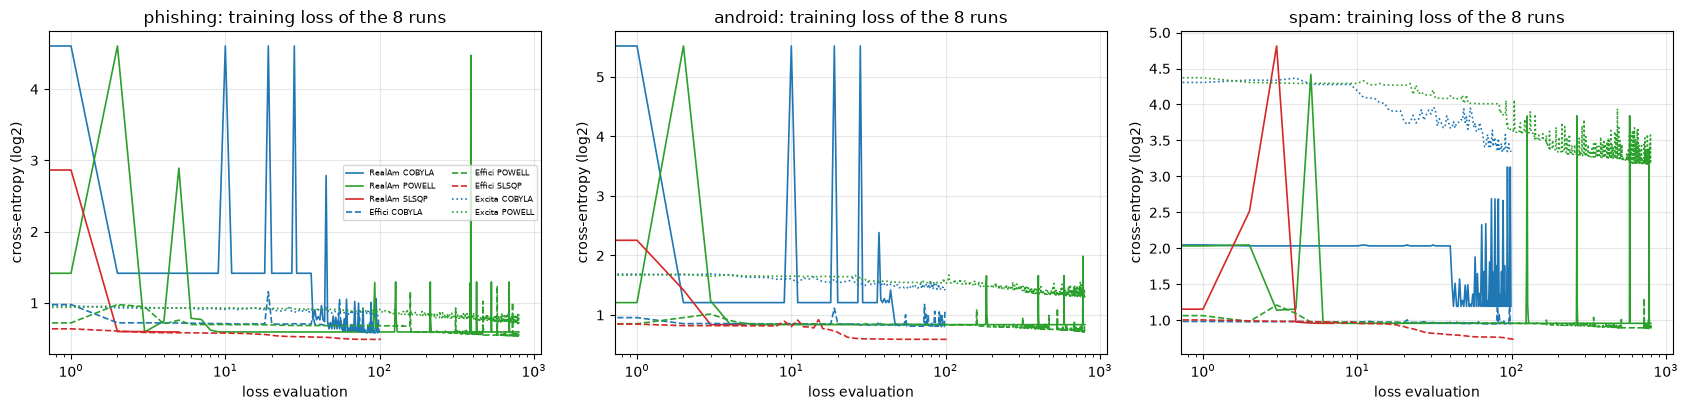

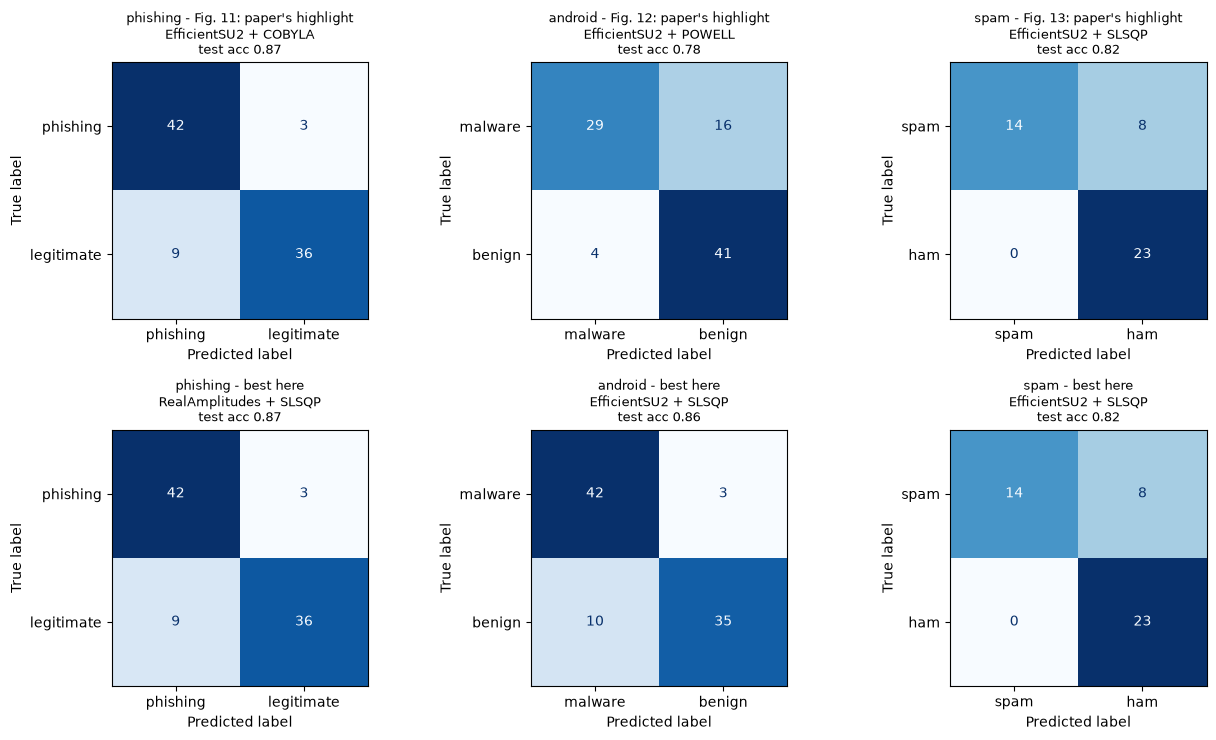

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
cm = {"COBYLA": "tab:blue", "POWELL": "tab:green", "SLSQP": "tab:red"}; ls = {"RealAmplitudes": "-", "EfficientSU2": "--", "ExcitationPreserving": ":"}
for ax, key in zip(axes, ("phishing", "android", "spam")):
    for (k, a, o), r in RESULTS.items():
        if k == key and r: ax.plot(r["hist"], color=cm[o], ls=ls[a], lw=1.2, label=f"{a[:6]} {o}")
    ax.set_xlabel("loss evaluation"); ax.set_ylabel("cross-entropy (log2)"); ax.set_title(f"{key}: training loss of the 8 runs"); ax.grid(alpha=0.3); ax.set_xscale("log")
axes[0].legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show()

HIGHLIGHT = {"phishing": ("EfficientSU2", "COBYLA", 11), "android": ("EfficientSU2", "POWELL", 12), "spam": ("EfficientSU2", "SLSQP", 13)}
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for j, key in enumerate(("phishing", "android", "spam")):
    d = D[key]; a, o, fno = HIGHLIGHT[key]
    best = max((v for (k, _, _), v in RESULTS.items() if k == key and v), key=lambda v: (v["test_acc"], -v["fit_s"]))
    for i, (r, ttl) in enumerate(((RESULTS[(key, a, o)], f"Fig. {fno}: paper's highlight\n{a} + {o}"), (best, f"best here\n{best['ansatz']} + {best['optimiser']}"))):
        ConfusionMatrixDisplay(confusion_matrix(d["y_te"], r["pred_te"], labels=[1, 0]), display_labels=[d["spec"]["attack_name"], d["spec"]["benign_name"]]).plot(ax=axes[i, j], colorbar=False, cmap="Blues")
        axes[i, j].set_title(f"{key} - {ttl}\ntest acc {r['test_acc']:.2f}", fontsize=9)
plt.tight_layout(); plt.show()

### Seed study

The paper reports one run per cell. How much of a cell's number is the random starting point? `COBYLA` with the two cheapest ansaetze is repeated from
`N_SEED_REPEATS` further initial points on the same split.

In [15]:
seed_rows = []
for key in ("phishing", "android", "spam"):
    for a in ("RealAmplitudes", "EfficientSU2"):
        accs = [RESULTS[(key, a, "COBYLA")]["test_acc"]] + [fit_vqc(key, a, "COBYLA", seed=SEED + 100 + s)["test_acc"] for s in range(N_SEED_REPEATS)]
        seed_rows.append(dict(dataset=key, ansatz=a, optimiser="COBYLA", runs=len(accs), test_acc_mean=round(np.mean(accs), 3), test_acc_std=round(np.std(accs), 3),
                              min=round(min(accs), 2), max=round(max(accs), 2)))
seed_df = pd.DataFrame(seed_rows); display(seed_df)

,dataset,ansatz,optimiser,runs,test_acc_mean,test_acc_std,min,max
0,phishing,RealAmplitudes,COBYLA,3,0.867,0.000,0.87,0.87
1,phishing,EfficientSU2,COBYLA,3,0.867,0.000,0.87,0.87
2,android,RealAmplitudes,COBYLA,3,0.667,0.000,0.67,0.67
3,android,EfficientSU2,COBYLA,3,0.667,0.000,0.67,0.67
4,spam,RealAmplitudes,COBYLA,3,0.578,0.048,0.51,0.62
5,spam,EfficientSU2,COBYLA,3,0.622,0.065,0.56,0.71


## 7. Classical against quantum (Tables 11, 12, 13) and the second phishing set (Table 15)

Tables 11-13 repeat the SVC row of Table 7 next to the two VQC combinations the paper singles out for each dataset. Table 15 re-runs the whole pipeline on the second phishing
dataset (reduced to the 9 features of Table 14) for the two combinations `RealAmplitudes` + `SLSQP` and `EfficientSU2` + `COBYLA`. The paper does not state the sample size of that
working set; this notebook uses the same 150 + 150 as the first phishing set (CHOICE).

In [16]:
for key, ans_opt in (("phishing2", [("RealAmplitudes", "SLSQP"), ("EfficientSU2", "COBYLA")]),):
    print(f"=== {SPECS[key]['title']} ({D[key]['X_tr'].shape[1]} qubits, {len(D[key]['y_tr'])} training records) ===")
    for a, o in ans_opt:
        RESULTS[(key, a, o)] = fit_vqc(key, a, o); r = RESULTS[(key, a, o)]
        print(f"  {a:15s} {o:7s} train {r['train_acc']:.3f} test {r['test_acc']:.3f} | {r['evals']} evals | {r['fit_s']:.1f} s | stopped by cap: {r['stopped']}")

COMPARE = {  # table: dataset -> list of (label, ansatz, optimiser, paper train, paper test)
 "Table 13 (phishing)": ("phishing", [("EfficientSU2 + COBYLA", "EfficientSU2", "COBYLA", 0.85, 0.92), ("RealAmp + SLSQP", "RealAmplitudes", "SLSQP", 0.85, 0.92)], PAPER_T7["phishing"]),
 "Table 12 (Android)":  ("android",  [("EfficientSU2 + POWELL", "EfficientSU2", "POWELL", 0.87, 0.90), ("RealAmp + COBYLA", "RealAmplitudes", "COBYLA", 0.70, 0.72)], PAPER_T7["android"]),
 "Table 11 (spam)":     ("spam",     [("EfficientSU2 + SLSQP", "EfficientSU2", "SLSQP", 0.84, 0.80), ("RealAmp + COBYLA", "RealAmplitudes", "COBYLA", 0.68, 0.83)], PAPER_T7["spam"]),
 "Table 15 (phishing 2)": ("phishing2", [("RealAmp + SLSQP", "RealAmplitudes", "SLSQP", 0.78, 0.73), ("EfficientSU2 + COBYLA", "EfficientSU2", "COBYLA", 0.76, 0.70)], (0.97, 0.87)),
}
rows = []
for tname, (key, combos, (ptr, pte)) in COMPARE.items():
    rows.append(dict(table=tname, model="classical SVC", paper_train=ptr, paper_test=pte, nb_train=SVC_RES[key][0], nb_test=SVC_RES[key][1]))
    for lab, a, o, ptr_, pte_ in combos:
        r = RESULTS[(key, a, o)]
        rows.append(dict(table=tname, model="QML: ZFeatureMap + " + lab, paper_train=ptr_, paper_test=pte_, nb_train=round(r["train_acc"], 2), nb_test=round(r["test_acc"], 2)))
cmp_df = pd.DataFrame(rows); display(cmp_df)

=== Website phishing 2 (11,055 sites) (9 qubits, 210 training records) ===


  RealAmplitudes  SLSQP   train 0.605 test 0.589 | 7 evals | 4.2 s | stopped by cap: False


  EfficientSU2    COBYLA  train 0.724 test 0.711 | 100 evals | 36.5 s | stopped by cap: False


,table,model,paper_train,paper_test,nb_train,nb_test
0,Table 13 (phishing),classical SVC,0.92,0.93,0.938,0.922
1,Table 13 (phishing),QML: ZFeatureMap + EfficientSU2 + COBYLA,0.85,0.92,0.880,0.870
2,Table 13 (phishing),QML: ZFeatureMap + RealAmp + SLSQP,0.85,0.92,0.880,0.870
3,Table 12 (Android),classical SVC,0.99,0.98,0.924,0.933
4,Table 12 (Android),QML: ZFeatureMap + EfficientSU2 + POWELL,0.87,0.90,0.810,0.780
5,Table 12 (Android),QML: ZFeatureMap + RealAmp + COBYLA,0.70,0.72,0.710,0.670
6,Table 11 (spam),classical SVC,0.93,0.87,0.914,0.822
7,Table 11 (spam),QML: ZFeatureMap + EfficientSU2 + SLSQP,0.84,0.80,0.900,0.820
8,Table 11 (spam),QML: ZFeatureMap + RealAmp + COBYLA,0.68,0.83,0.500,0.510
9,Table 15 (phishing 2),classical SVC,0.97,0.87,0.943,0.900


## 8. Paper against this notebook, claim by claim

A numeric claim is **reproduced** when this notebook's value is within `TOL` = 0.02 of the paper's (about two test records), **not reached** when it is lower by more
than that, **exceeded** when higher; the `within_0.05` column shows the looser band. Qualitative claims are tested on this notebook's own results and, for the first
one, on the paper's own tables as well. Times and the Intel-versus-Apple claim are not checkable on one machine.

In [17]:
def verdict(paper, ours, tol=TOL):
    if paper == "*" or ours is None: return "cannot be checked"
    return "reproduced" if abs(ours - paper) <= tol else ("exceeded" if ours > paper else "not reached")

claims = []
for key in ("phishing", "android", "spam"):                        # Table 7
    for j, nm in enumerate(("train", "test")):
        claims.append(dict(claim=f"Table 7 SVC {key} {nm} accuracy", paper=PAPER_T7[key][j], notebook=round(SVC_RES[key][j], 3)))
for (key, a, o), p in PAPER_T.items():                              # Tables 8-10
    r = RESULTS.get((key, a, o))
    for j, nm in enumerate(("train", "test")):
        claims.append(dict(claim=f"{SPECS[key]['table']} {key} {a} + {o} {nm}", paper=p[j] if p else "*", notebook=round(r["train_acc" if j == 0 else "test_acc"], 3) if r else None))
for (tname, (key, combos, (ptr, pte))) in COMPARE.items():           # Table 15 only (11-13 repeat entries of Tables 8-10)
    if tname.startswith("Table 15"):
        claims.append(dict(claim="Table 15 SVC phishing2 test", paper=pte, notebook=round(SVC_RES[key][1], 3)))
        for lab, a, o, ptr_, pte_ in combos:
            claims.append(dict(claim=f"Table 15 {a} + {o} test", paper=pte_, notebook=round(RESULTS[(key, a, o)]["test_acc"], 3)))
claims_df = pd.DataFrame(claims)
claims_df["verdict"] = [verdict(p, n) for p, n in zip(claims_df.paper, claims_df.notebook)]
claims_df["within_0.05"] = [("yes" if (p != "*" and n is not None and abs(n - p) <= TOL_WIDE) else "no" if p != "*" and n is not None else "-") for p, n in zip(claims_df.paper, claims_df.notebook)]
claims_df["gap"] = [round(n - p, 3) if (p != "*" and n is not None) else None for p, n in zip(claims_df.paper, claims_df.notebook)]
display(claims_df)
print(claims_df.verdict.value_counts().to_string())
num = claims_df[claims_df.verdict != "cannot be checked"]
print(f"\nwithin 0.02: {(num.verdict == 'reproduced').sum()} of {len(num)}   within 0.05: {(num['within_0.05'] == 'yes').sum()} of {len(num)}")

,claim,paper,notebook,verdict,within_0.05,gap
0,Table 7 SVC phishing train accuracy,0.92,0.938,reproduced,yes,0.018
1,Table 7 SVC phishing test accuracy,0.93,0.922,reproduced,yes,-0.008
2,Table 7 SVC android train accuracy,0.99,0.924,not reached,no,-0.066
3,Table 7 SVC android test accuracy,0.98,0.933,not reached,yes,-0.047
4,Table 7 SVC spam train accuracy,0.93,0.914,reproduced,yes,-0.016
...,...,...,...,...,...,...
58,Table 10 spam ExcitationPreserving + SLSQP train,*,NaN,cannot be checked,-,NaN
59,Table 10 spam ExcitationPreserving + SLSQP test,*,NaN,cannot be checked,-,NaN
60,Table 15 SVC phishing2 test,0.87,0.900,exceeded,yes,0.030
61,Table 15 RealAmplitudes + SLSQP test,0.73,0.589,not reached,no,-0.141


verdict
not reached          24
exceeded             24
reproduced            9
cannot be checked     6

within 0.02: 9 of 57   within 0.05: 21 of 57


In [18]:
# --- qualitative conclusions of Section 6.2 and 7, tested on the paper's own tables and on this notebook ---
def mean_test(src, key, **sel):
    vals = []
    for a in ANSATZE:
        for o in OPTIMISERS:
            if sel.get("a") not in (None, a) or sel.get("o") not in (None, o): continue
            v = src(key, a, o)
            if v is not None: vals.append(v)
    return float(np.mean(vals)) if vals else np.nan
paper_src = lambda k, a, o: (PAPER_T[(k, a, o)][1] if PAPER_T[(k, a, o)] else None)
nb_src    = lambda k, a, o: (RESULTS[(k, a, o)]["test_acc"] if RESULTS.get((k, a, o)) else None)

q = []
for label, src in (("paper's tables", paper_src), ("this notebook", nb_src)):
    for key in ("phishing", "android", "spam"):
        by_a = [mean_test(src, key, a=a) for a in ANSATZE]; by_o = [mean_test(src, key, o=o) for o in OPTIMISERS]
        # (i) "results from ansatz are not as decisive as those from the optimisation algorithms"
        q.append(dict(source=label, dataset=key, claim="spread of mean test acc over ansaetze", value=round(np.nanmax(by_a) - np.nanmin(by_a), 3)))
        q.append(dict(source=label, dataset=key, claim="spread of mean test acc over optimisers", value=round(np.nanmax(by_o) - np.nanmin(by_o), 3)))
        ea = [mean_test(src, key, a=a) for a in ("RealAmplitudes", "EfficientSU2")]
        q.append(dict(source=label, dataset=key, claim="ExcitationPreserving mean test acc minus mean of the other two", value=round(by_a[2] - np.nanmean(ea), 3)))
        best = max(((src(key, a, o), a, o) for a in ANSATZE for o in OPTIMISERS if src(key, a, o) is not None), key=lambda t: t[0])
        q.append(dict(source=label, dataset=key, claim="best cell (test acc, ansatz, optimiser)", value=f"{best[0]:.2f} {best[1]} + {best[2]}"))
qdf = pd.DataFrame(q).pivot(index=["dataset", "claim"], columns="source", values="value")
display(qdf)

def ok(c): return "reproduced" if c else "not reached"
summary = []
for label, src in (("paper's tables", paper_src), ("this notebook", nb_src)):
    opt_gt_ans = sum((np.nanmax([mean_test(src, k, o=o) for o in OPTIMISERS]) - np.nanmin([mean_test(src, k, o=o) for o in OPTIMISERS])) >
                     (np.nanmax([mean_test(src, k, a=a) for a in ANSATZE]) - np.nanmin([mean_test(src, k, a=a) for a in ANSATZE])) for k in ("phishing", "android", "spam"))
    ep_worst = sum(mean_test(src, k, a="ExcitationPreserving") < min(mean_test(src, k, a="RealAmplitudes"), mean_test(src, k, a="EfficientSU2")) for k in ("phishing", "android", "spam"))
    best_ok = sum(max(((src(k, a, o), o) for a in ANSATZE for o in OPTIMISERS if src(k, a, o) is not None))[1] in ("SLSQP", "POWELL") for k in ("phishing", "android", "spam"))
    summary.append(dict(source=label, **{"optimiser spread > ansatz spread (datasets of 3)": opt_gt_ans, "ExcitationPreserving worst ansatz (of 3)": ep_worst, "best cell uses SLSQP or POWELL (of 3)": best_ok}))
display(pd.DataFrame(summary).set_index("source"))

gap_rows = []
for tname, (key, combos, (ptr, pte)) in COMPARE.items():
    best_q = max(RESULTS[(key, a, o)]["test_acc"] for _, a, o, _, _ in combos)
    best_p = max(c[4] for c in combos)
    gap_rows.append(dict(table=tname, paper_gap_SVC_minus_best_QML_test=round(pte - best_p, 2), notebook_gap=round(SVC_RES[key][1] - best_q, 3)))
display(pd.DataFrame(gap_rows))
ep_t = np.nanmean([RESULTS[(k, "ExcitationPreserving", o)]["fit_s"] / max(RESULTS[(k, "ExcitationPreserving", o)]["evals"], 1) for k in ("phishing", "android", "spam") for o in ("COBYLA", "POWELL")])
su_t = np.nanmean([RESULTS[(k, "EfficientSU2", o)]["fit_s"] / max(RESULTS[(k, "EfficientSU2", o)]["evals"], 1) for k in ("phishing", "android", "spam") for o in ("COBYLA", "POWELL")])
print(f"seconds per loss evaluation: ExcitationPreserving {ep_t:.3f} s vs EfficientSU2 {su_t:.3f} s  ->  ExcitationPreserving is {ep_t/su_t:.1f}x slower per evaluation (paper: 'increases the processing time')")
print("Intel vs Apple Silicon (Section 6.3): cannot be checked on one machine.")
print("ExcitationPreserving + SLSQP ('*', > 12 h in the paper):", "run here" if RUN_EP_SLSQP else "not run here (RUN_EP_SLSQP = False); with the adjoint gradient it is feasible, set the flag to see it")

source                                                                     paper's tables                 this notebook
dataset  claim                                                                                                         
android  ExcitationPreserving mean test acc minus mean o...                        -0.303                        -0.022
         best cell (test acc, ansatz, optimiser)               0.90 EfficientSU2 + POWELL     0.86 EfficientSU2 + SLSQP
         spread of mean test acc over ansaetze                                      0.307                           0.1
         spread of mean test acc over optimisers                                    0.237                         0.102
phishing ExcitationPreserving mean test acc minus mean o...                        -0.368                        -0.191
         best cell (test acc, ansatz, optimiser)              0.92 RealAmplitudes + SLSQP  0.87 RealAmplitudes + COBYLA
         spread of mean test acc over ansaetze                                       0.47                         0.194
         spread of mean test acc over optimisers                                    0.277                          0.07
spam     ExcitationPreserving mean test acc minus mean o...                        -0.283                        -0.159
         best cell (test acc, ansatz, optimiser)             0.83 RealAmplitudes + COBYLA     0.82 EfficientSU2 + SLSQP
         spread of mean test acc over ansaetze                                      0.333                         0.244
         spread of mean test acc over optimisers                                    0.217                         0.144

,optimiser spread > ansatz spread (datasets of 3),ExcitationPreserving worst ansatz (of 3),best cell uses SLSQP or POWELL (of 3)
source,,,
paper's tables,0,3,2
this notebook,1,2,3


,table,paper_gap_SVC_minus_best_QML_test,notebook_gap
0,Table 13 (phishing),0.01,0.055
1,Table 12 (Android),0.08,0.155
2,Table 11 (spam),0.04,-0.000
3,Table 15 (phishing 2),0.14,0.189


seconds per loss evaluation: ExcitationPreserving 1.199 s vs EfficientSU2 0.661 s  ->  ExcitationPreserving is 1.8x slower per evaluation (paper: 'increases the processing time')
Intel vs Apple Silicon (Section 6.3): cannot be checked on one machine.
ExcitationPreserving + SLSQP ('*', > 12 h in the paper): not run here (RUN_EP_SLSQP = False); with the adjoint gradient it is feasible, set the flag to see it


## Reading the paper critically

**The headline conclusion ("ansatz matters less than optimiser") is not what the paper's own tables show.** Averaging each table over optimisers
and over ansaetze, the spread between ansaetze (driven by `ExcitationPreserving`, 0.40-0.50 test accuracy) is larger than the spread between optimisers in all three
tables (0 of 3 datasets favour the claim). (The paper's best test cell is `SLSQP` or `POWELL` on phishing and Android but `RealAmplitudes` + `COBYLA` on spam.) The qualitative block of
Section 8 computes these spreads on both the paper's numbers and this notebook's; here the optimiser spread exceeds the ansatz spread in 1 of 3 datasets (Android, 0.102 vs 0.100, a tie).
`ExcitationPreserving` is the worst ansatz in 2 of 3 datasets here (not on Android, where its `POWELL` run reaches 0.74 against 0.67 for `RealAmplitudes`), and it costs about 1.8x
more time per loss evaluation than `EfficientSU2`.

**`RealAmplitudes` without entanglement is a one-qubit classifier.** The class is read from qubit 0 only (`x mod 2`), `ZFeatureMap` creates no entanglement and the
paper removed the entangling layer of `RealAmplitudes`. The whole circuit is therefore a product state, and the prediction depends on a single feature (the one on qubit 0)
and four rotation angles. The baseline table in Section 3 confirms it: an SVC given only that one feature reaches 0.87 (phishing), 0.67 (Android) and 0.62 (spam) test accuracy,
exactly the values of the `RealAmplitudes` cells that trained (0.87, 0.67, 0.62). Their good phishing number says more about the `SFH` feature than about quantum learning.
Exercise 1 puts the CNOT chain back.

**100 COBYLA evaluations do not fit the larger ansaetze.** COBYLA first evaluates a simplex of (parameters + 1) points. With 100 evaluations `ExcitationPreserving` (144-175
parameters) never completes it, and `EfficientSU2` (72-80) has only 20-30 evaluations left; this is the likely reason for the paper's chance-level `ExcitationPreserving` + `COBYLA`
cells and, here, for runs that stay at their starting accuracy (the seed study shows identical test accuracies for three different starting points on phishing and Android).
Reading the `ExcitationPreserving` result as "that ansatz is bad" confuses an ansatz property with an optimiser budget.

**All `VQC` read-outs use qubit 0.** For two classes Qiskit's `VQC` maps a bit-string to `x % 2`, not to its parity; for the entangling ansaetze the other qubits matter only
through correlations with qubit 0.

**Test sets of 90 and 45 records.** One record is 0.011 (phishing, Android) or 0.022 (spam) of accuracy; the binomial standard error near 0.85 is about 0.04 (0.05
for spam). Differences of 0.02-0.05 between table cells, and statements such as "closest to the classical result", are inside that noise. The paper reports one run per cell
and one split; the seed study above shows how much a different starting point alone moves a cell.

**Test accuracy above training accuracy.** Several cells (0.85 train / 0.92 test; spam `RealAmplitudes` + `COBYLA` 0.68 / 0.83) have a higher test than training
accuracy, which for a model fitted on training data signals a small, unlucky or unrepresentative split rather than skill.

**Feature selection saw the test records.** The 9 Android permissions and 10 spam words were chosen by correlation and ANOVA on the full file. The leakage-free ANOVA
selection computed in Section 3 picks 8 of the 9 Android permissions but only 4 of the 10 spam words (overlap column); the classical test accuracy hardly moves (Android 0.93 -> 0.93,
spam 0.82 -> 0.80), so on these data the leak is small, but it is a leak.

**The classical baseline is a default SVC without tuning, and the quantum models are given the same 9-10 numbers.** On the 1,353-site phishing file a plain linear or
RBF model reaches the same 0.92-0.93 (here 0.92); on Android the paper's SVC reaches 0.98 test, here 0.93 (the random forest on all features reaches 0.97). The paper's "approaching
classical results" holds in this notebook only for spam (the best VQC equals the SVC at 0.82); on phishing the best VQC is 0.055 below the SVC, on Android 0.155 below (paper: 0.01 and 0.08),
and on the second phishing set the gap is 0.19 (paper: 0.14; Table 15: 0.87 vs 0.70-0.73 test).

**Wall time compares simulators, not quantum speed.** Table 8-10 times are classical simulation times of an exact state-vector run; the Intel-vs-Apple discussion in
Section 6.3 is about NumPy / BLAS on two CPUs and says nothing about quantum computation. The "12 h" cut-off cell is a property of the simulator's parameter-shift gradient
(this notebook's adjoint gradient makes it cheap).

**Small inconsistencies.** The Android fig. 12 caption says COBYLA while the text and Table 9 say POWELL; the Android file has 29,332 rows in the UCI archive (the paper says
29,932); the second phishing file is described with 31 attributes (30 features + label). None changes a conclusion.

## Exercises

1. **Entangle `RealAmplitudes`.** Set `RA_ENTANGLEMENT = "reverse_linear"` (Section 0) and rerun the Phishing grid. How much of the paper's `RealAmplitudes` row was caused by removing the CNOTs?
2. **Read-out.** Replace the read-out `x mod 2` by the parity of all bits (change `p1` in `FastVQC.probs`; check the equivalence cell, which compares against Qiskit's default, and say what it now tests).
3. **Depth.** Vary `ANSATZ_REPS` in {1, 2, 3, 5}. Does a deeper `EfficientSU2` help `COBYLA` within 100 evaluations?
4. **Fair optimiser comparison.** Give `COBYLA` the same number of loss evaluations that `POWELL` used (look at the `evals` column) and compare. How much of the paper's "optimiser" effect is just budget?
5. **Leakage.** Redo Section 2 with `cols="anova"` (train-split-only ANOVA selection) and rerun the Android and Spam grids. Which of the paper's best cells survive?